# Predicting Mortality in Canadian Individual Life Insurance with Neural Networks
### A comparison with the CIA2014 table and a Poisson GLM

**MGSC 673 – Individual Deep Learning Project** · Rina Xu · McGill MMA

---

**Question.** Life insurers price and reserve using mortality tables. In Canada the reference table is **CIA2014**, which depends mainly on sex, smoking status, issue age and policy duration. Real insured mortality also depends on underwriting class, product type, face amount and their interactions. *Can a neural network trained on industry experience predict deaths more accurately than (i) the CIA2014 table and (ii) a Poisson GLM, the standard actuarial model — and what does it learn that the table misses?*

**Data.** Canadian Institute of Actuaries, *Canadian Individual Life Experience Updated to Policy Year 2023-2024 – Database 2010-2024* (https://www.cia-ica.ca/publications/226068de/). Each row is a cell of insured lives sharing the same characteristics in one policy year, with exposure, deaths and CIA2014 expected deaths.

**Notebook map**
1. Setup
2. Data: loading, quality checks, exploratory analysis, preprocessing, time-based split
3. Benchmarks: CIA2014 table and Poisson GLMs
4. Neural network: architecture, Poisson loss with exposure offset, training
5. Experiments: a sequence of rounds — optimisation, capacity, regularisation, inputs/data window, model structure (CANN), ensembling
6. Final evaluation on the held-out policy year 2023-24
7. Using the model: segment A/E analysis, what the network learned, pricing a 20-year term product
8. Conclusions and limitations

**How to run.** Put the CIA CSV files (`ILMSdb0910.csv` … `ILMSdb2324.csv`) in a folder `data/` next to this notebook (download the zip from the link above). Requirements: Python 3.10+, `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `torch` (CPU is enough, no GPU needed).
* Every network trained in this notebook (~35 runs) is saved to `models/runs/` under a name derived from its configuration. With `RETRAIN = False` (Section 1), *Restart & Run All* re-loads these saved weights and recomputes every result in a few minutes.
* With `RETRAIN = True`, or if `models/runs/` is missing, all networks are retrained from scratch. This took **about 2 hours on a 2-core CPU** (the [256,128,64] network runs of Rounds 3–6 are the slowest, 3–13 minutes each). Small numerical differences across machines are possible when retraining.
* Figures are saved to `figures/`, result tables to `results/`, the final ensemble to `models/final_ensemble.pt`.

## 1. Setup

Install the required packages once (only needed on a new machine):

In [1]:
%pip install numpy pandas matplotlib scikit-learn torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, json, copy, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import torch
import torch.nn as nn
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import SplineTransformer

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("all libraries loaded, torch", torch.__version__)

all libraries loaded, torch 2.14.0+cpu


In [3]:
DATA_DIR = "data"
RETRAIN = False
for d in ["figures", "results", "models", "models/runs"]:
    os.makedirs(d, exist_ok=True)

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
set_seed()
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

C = {"CIA2014": "#898781", "GLM": "#eb6834", "NN": "#2a78d6", "CANN": "#1baf7a",
     "NN (CIA offset)": "#6250d6", "Ensemble": "#2a78d6", "Actual": "#0b0b0b"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.color": "#898781", "ytick.color": "#898781", "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
def savefig(name):
    plt.savefig(f"figures/{name}.png"); plt.show()

print("files in data/:", len(os.listdir(DATA_DIR)))

files in data/: 15


## 2. Data
### 2.1 Load all 15 policy years
The archive contains one CSV per policy year (2009-10 to 2023-24). Each file has ~0.5–0.8 M rows. Only the columns needed are loaded, with compact integer types, so all 15 years fit in well under 1 GB of memory.

In [4]:
YEARS = ["0910","1011","1112","1213","1314","1415","1516","1617","1718","1819","1920","2021","2122","2223","2324"]
KEYS_RAW = ["Year","Sex","Smoke","PfdType","PolTypGrp","Base","Par","Size","IssueAge","PolYear","AttdAge"]
VALS = ["ExposCnt","ExposAmt","DthCnt","DthAmt","ExpecCnt","ExpecAmt"]

t0 = time.time()
raw = pd.concat([pd.read_csv(f"{DATA_DIR}/ILMSdb{y}.csv", usecols=KEYS_RAW + VALS,
                             dtype={k: "int16" for k in KEYS_RAW}) for y in YEARS], ignore_index=True)
raw["CalYear"] = 2000 + raw["Year"] // 100
print(f"{len(raw):,} rows loaded in {time.time()-t0:.1f}s")
raw.head()

9,968,712 rows loaded in 8.4s


,Year,Sex,Smoke,PfdType,PolTypGrp,Base,Par,Size,IssueAge,PolYear,AttdAge,ExposCnt,ExposAmt,DthCnt,DthAmt,ExpecCnt,ExpecAmt,CalYear
0,910,1,1,1,1,1,0,1,0,17,16,0.5,0.5,0.5,0.5,0.500000,0.500,2009
1,910,1,1,1,1,1,0,1,0,17,16,0.5,4999.5,-0.5,-0.5,-0.499690,1.065,2009
2,910,1,1,1,1,1,0,1,0,18,17,1.0,5000.0,0.0,0.0,0.000382,1.910,2009
3,910,1,1,1,1,1,0,1,0,20,19,2.0,10000.0,0.0,0.0,0.001036,5.180,2009
4,910,1,1,1,1,1,0,1,0,21,20,2.0,10000.0,0.0,0.0,0.001158,5.790,2009


**Variables** (from the CIA field descriptions)

| Field | Meaning |
|---|---|
| Sex | 1 = male, 2 = female |
| Smoke | 1 = smoker, 2 = non-smoker, 3 = aggregate/unknown |
| PfdType | underwriting class: 1 = non-preferred, 2 = residual, 3 = preferred |
| PolTypGrp | 1 Whole Life, 2 Term-to-100, 3 UL increasing COI, 4 UL level COI, 5 UL limited pay, 6 Term10, 7 Term20, 8 Other term, 9 Other |
| Base / Par | base vs rider; participating vs non-par |
| Size | face-amount band: 1 = 0–10k, 2 = 10–50k, 3 = 50–100k, 4 = 100–250k, 5 = 250–500k, 6 = 500k–1M, 7 = 1–2M, 8 = 2M+ |
| IssueAge, PolYear, AttdAge | age at issue, policy year (duration), attained age = IssueAge + PolYear − 1 |
| ExposCnt / DthCnt | policy-years exposed / deaths (**the target**) |
| ExpecCnt | expected deaths under CIA2014 = q × ExposCnt (**benchmark**) |

### 2.2 Data-quality checks
Before modelling, check for things that would silently break a Poisson model (negative or zero exposure, non-integer counts, constant columns, missing values).

In [5]:
checks = {
    "missing values": int(raw.isna().sum().sum()),
    "rows with ExposCnt <= 0": int((raw.ExposCnt <= 0).sum()),
    "  ...of which ExposCnt < 0": int((raw.ExposCnt < 0).sum()),
    "  ...deaths in rows with ExposCnt <= 0": float(raw.loc[raw.ExposCnt <= 0, "DthCnt"].sum()),
    "rows with negative DthCnt": int((raw.DthCnt < 0).sum()),
    "rows with non-integer DthCnt": int((raw.DthCnt % 1 != 0).sum()),
    "distinct values of Base": sorted(raw.Base.unique().tolist()),
    "exposure with Base = 0 (riders)": float(raw.loc[raw.Base == 0, "ExposCnt"].sum()),
    "rows with ExpecCnt <= 0 but ExposCnt > 0": int(((raw.ExpecCnt <= 0) & (raw.ExposCnt > 0)).sum()),
    "total deaths (all years)": float(raw.DthCnt.sum()),
}
pd.Series(checks, name="value").to_frame()

,value
missing values,0
rows with ExposCnt <= 0,1340102
...of which ExposCnt < 0,648
...deaths in rows with ExposCnt <= 0,423.0
rows with negative DthCnt,15
rows with non-integer DthCnt,118800
distinct values of Base,"[0, 1]"
exposure with Base = 0 (riders),0.0
rows with ExpecCnt <= 0 but ExposCnt > 0,178
total deaths (all years),1049171.0


Findings and decisions:
* **Split first record.** The CIA documentation explains that the first record of each file is split in two (the first copy has 0.5 in every numeric field) so that database programs read the columns as decimals. The second copy is adjusted so totals are right. This produces the one row per file with −0.5 deaths. **Decision:** re-aggregate rows by their key; the two halves merge back into one valid record.
* **Zero/negative exposure.** About 1.3 M rows have zero exposure (and a handful have small negative exposure, which are accounting adjustments). They carry only a few hundred deaths out of ~1 M. A Poisson model needs exposure > 0 (we take its log). **Decision:** drop rows whose exposure is ≤ 0 *after* aggregation.
* **Half deaths (x.5).** Deaths are recorded in halves in some cells (consistent with the study's exposure convention). The Poisson deviance is defined for non-negative real counts, so **no change is needed**.
* **Base is constant** (all exposure is on base policies; riders have zero exposure in this database). **Decision:** drop the column.

### 2.3 Exploratory analysis
**Mortality over time.** The A/E ratio (actual deaths ÷ CIA2014 expected deaths) by policy year shows how industry experience moves relative to a fixed table.

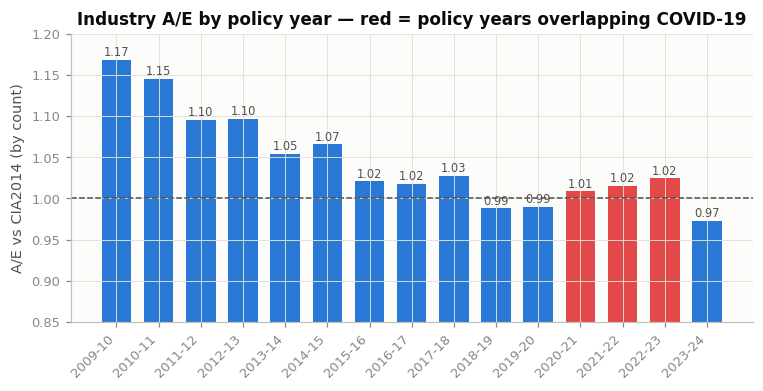

,ExposCnt,DthCnt,ExpecCnt,A/E,crude q per 1000,rows
CalYear,,,,,,
2009,9110914.197,64313.0,55033.482,1.169,7.059,517796
2010,9135182.902,64866.5,56634.571,1.145,7.101,525955
2011,8646026.719,62929.0,57451.635,1.095,7.278,620343
2012,8804167.393,65368.0,59622.425,1.096,7.425,648622
2013,8168122.625,63098.0,59870.100,1.054,7.725,624301
2014,8742992.963,68278.0,64067.898,1.066,7.809,639109
2015,8708040.169,67206.0,65839.113,1.021,7.718,657263
2016,8208790.815,66639.5,65497.838,1.017,8.118,646171
2017,8760743.949,70618.5,68767.087,1.027,8.061,682527


In [6]:
by_year = raw.groupby("CalYear")[["ExposCnt", "DthCnt", "ExpecCnt"]].sum()
by_year["A/E"] = by_year.DthCnt / by_year.ExpecCnt
by_year["crude q per 1000"] = 1000 * by_year.DthCnt / by_year.ExposCnt
by_year["rows"] = raw.groupby("CalYear").size()

fig, ax = plt.subplots(figsize=(8, 3.4))
lab = [f"{y}-{str(y+1)[2:]}" for y in by_year.index]
cols = ["#e34948" if y in (2020, 2021, 2022) else C["NN"] for y in by_year.index]
ax.bar(range(len(by_year)), by_year["A/E"], color=cols, width=0.7)
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_xticks(range(len(by_year))); ax.set_xticklabels(lab, rotation=45, ha="right")
ax.set_ylim(0.85, 1.2); ax.set_ylabel("A/E vs CIA2014 (by count)")
ax.set_title("Industry A/E by policy year — red = policy years overlapping COVID-19")
for i, v in enumerate(by_year["A/E"]): ax.text(i, v + 0.005, f"{v:.2f}", ha="center", fontsize=7.5, color="#52514e")
savefig("01_ae_by_year")
by_year.round(3)

Two things matter for the design:
1. **Mortality improves over time relative to the fixed table**: A/E falls from ~1.17 in 2009-10 to ~0.99 by 2018-20. A model trained on old years will over-predict recent deaths unless it captures this trend.
2. **COVID-19** pushes A/E back up in 2020-21 to 2022-23, and 2023-24 drops again to 0.97. The most recent year — our test set — is therefore not a simple continuation of the training years. This is a real-world forecasting challenge, and it is why the split must be by time (Section 2.5).

I use the **eight most recent policy years (2016-17 to 2023-24)** for modelling. Older years add volume but come from a different mortality level; eight years still give ~70 M policy-years of exposure and ~600 k deaths.

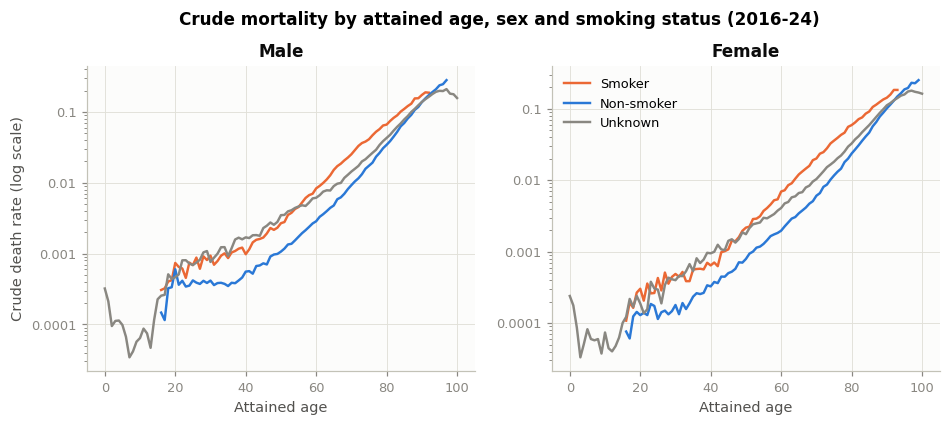

In [7]:
MODEL_YEARS = list(range(2016, 2024))
d0 = raw[raw.CalYear.isin(MODEL_YEARS)]
sm_lab = {1: "Smoker", 2: "Non-smoker", 3: "Unknown"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for sex, ax in zip([1, 2], axes):
    for sm, col in zip([1, 2, 3], ["#eb6834", C["NN"], "#898781"]):
        g = d0[(d0.Sex == sex) & (d0.Smoke == sm)].groupby("AttdAge")[["DthCnt", "ExposCnt"]].sum()
        g = g[g.ExposCnt > 2000]
        ax.plot(g.index, g.DthCnt / g.ExposCnt, color=col, label=sm_lab[sm], lw=1.6)
    ax.set_yscale("log"); ax.set_xlabel("Attained age"); ax.set_title(["Male", "Female"][sex - 1])
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
axes[0].set_ylabel("Crude death rate (log scale)"); axes[1].legend(loc="upper left")
plt.suptitle("Crude mortality by attained age, sex and smoking status (2016-24)", fontweight="bold", fontsize=11, y=1.02)
savefig("02_crude_q_by_age")

Mortality rises roughly exponentially with age (straight line on a log scale — the Gompertz law), smokers die at 2–3× the rate of non-smokers at the same age, and females are lighter than males. The "Unknown" smoking class is mostly older business where smoking status was not collected. These are the effects CIA2014 already captures. The next plot looks at factors the table does **not** use directly.

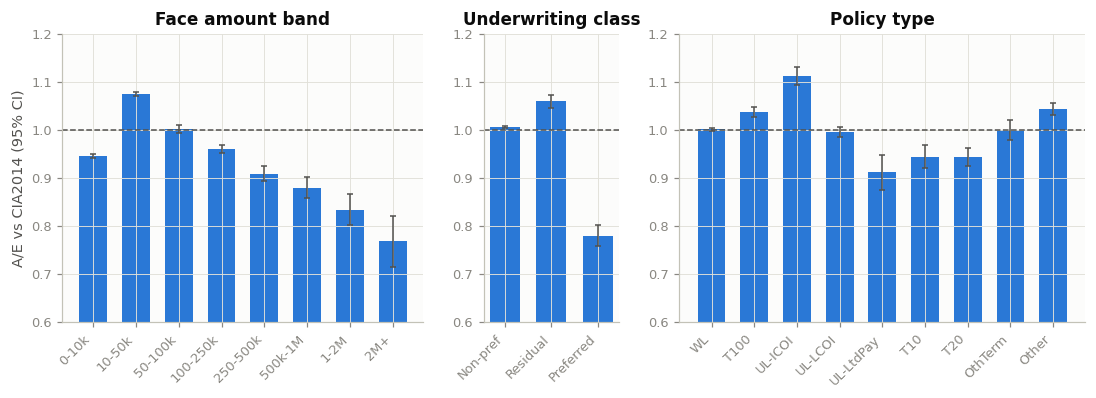

In [8]:
def ae_table(d, col, actual="DthCnt", expected="ExpecCnt"):
    g = d.groupby(col)[["ExposCnt", actual, expected]].sum()
    g["A/E"] = g[actual] / g[expected]
    g["se"] = np.sqrt(g[actual].clip(lower=1)) / g[expected]
    return g

size_lab = ["0-10k", "10-50k", "50-100k", "100-250k", "250-500k", "500k-1M", "1-2M", "2M+"]
pfd_lab = ["Non-pref", "Residual", "Preferred"]
pol_lab = ["WL", "T100", "UL-ICOI", "UL-LCOI", "UL-LtdPay", "T10", "T20", "OthTerm", "Other"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [8, 3, 9]})
for ax, col, labels, title in zip(axes, ["Size", "PfdType", "PolTypGrp"], [size_lab, pfd_lab, pol_lab],
                                  ["Face amount band", "Underwriting class", "Policy type"]):
    g = ae_table(d0, col)
    ax.bar(range(len(g)), g["A/E"], yerr=1.96 * g["se"], color=C["NN"], width=0.65,
           error_kw={"ecolor": "#52514e", "lw": 1, "capsize": 2})
    ax.axhline(1, color="#52514e", lw=1, ls="--"); ax.set_ylim(0.6, 1.2)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(labels, rotation=45, ha="right"); ax.set_title(title)
axes[0].set_ylabel("A/E vs CIA2014 (95% CI)")
savefig("03_ae_by_factor")

Relative to CIA2014, **larger policies have lighter mortality** (A/E falls from ~1.07 for 10–50k to ~0.77 for 2M+ — a classic socio-economic and underwriting effect), **preferred lives** are ~22% lighter than the table, and A/E varies by product. These systematic deviations are exactly what a data-driven model should be able to learn. Next: how sparse is the target?

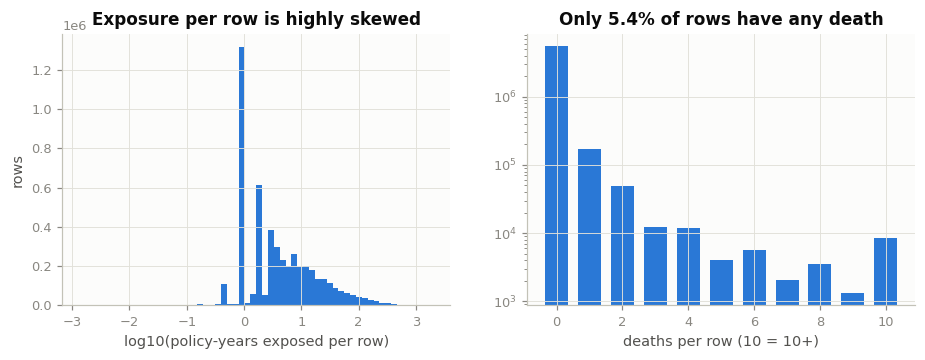

In [9]:
nz = (d0.DthCnt > 0).mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(np.log10(d0.loc[d0.ExposCnt > 0, "ExposCnt"]), bins=60, color=C["NN"])
axes[0].set_xlabel("log10(policy-years exposed per row)"); axes[0].set_ylabel("rows"); axes[0].set_title("Exposure per row is highly skewed")
vc = d0.DthCnt.clip(upper=10).round().value_counts().sort_index()
axes[1].bar(vc.index, vc.values, color=C["NN"], width=0.7); axes[1].set_yscale("log")
axes[1].set_xlabel("deaths per row (10 = 10+)"); axes[1].set_title(f"Only {nz:.1%} of rows have any death")
savefig("04_sparsity")

Most rows are tiny (a handful of policy-years) and **~95% of rows have zero deaths**. This rules out treating the death *rate* as a regression target with squared error: a row with 0.3 policy-years and 0 deaths and a row with 2,000 policy-years and 15 deaths must not get equal weight. The natural choice is a **Poisson likelihood with log-exposure as an offset**:
$$D_i \sim \text{Poisson}(\mu_i), \qquad \log \mu_i = \log E_i + f(x_i),$$
where $E_i$ is exposure and $f(x_i)=\log q(x_i)$ is the log mortality rate the model learns. Every model in this notebook (GLM and NN) uses this same likelihood, so they are directly comparable.

### 2.4 Preprocessing
* **Re-aggregate by key** (fixes the split record) after **capping policy duration at 21**. CIA2014 is a select-and-ultimate table with a 20-year select period, so durations 21+ are "ultimate" and the duration effect is assumed flat beyond that. **Attained age is kept exact** (it is part of the key), so capping duration loses no age information.
* *Troubleshooting note:* in my first version I capped duration and then **recomputed** attained age as IssueAge + capped duration − 1. That silently assigned, e.g., a policy issued at 25 and in its 60th year (true age 84) to age 45. The bug surfaced in the diagnostics: the baseline network's A/E by calendar year drifted from 0.77 (2016) to 1.04 (2021) even though the network had no year input — a sign that something in the inputs was mis-describing the mix of business. Keeping the original attained age fixed it.
* **Drop** rows with exposure ≤ 0 after aggregation, and the constant `Base` column.
* **Categoricals** (Sex, Smoke, PfdType, PolTypGrp, Par, Size) are integer-encoded for **embedding layers** in the network (one-hot for the GLM). Size is ordinal, but treating it as categorical lets the model learn a non-monotone pattern if one exists.
* **Numericals** (attained age, issue age, duration, calendar year) are standardised with the *training-set* mean and standard deviation (no information from validation/test leaks in).

In [10]:
DUR_CAP = 21
d = raw[raw.CalYear.isin(MODEL_YEARS)].copy()
d["PolYearC"] = d.PolYear.clip(upper=DUR_CAP)
keys = ["CalYear", "Sex", "Smoke", "PfdType", "PolTypGrp", "Par", "Size", "IssueAge", "PolYearC", "AttdAge"]
df = d.groupby(keys, as_index=False)[VALS].sum()
n_before = len(df)
df = df[(df.ExposCnt > 0) & (df.ExpecCnt > 0)].reset_index(drop=True)
print(f"rows after aggregation: {n_before:,} -> after dropping non-positive exposure: {len(df):,}")
print(f"deaths kept: {df.DthCnt.sum():,.0f} of {d.DthCnt.sum():,.0f} ({df.DthCnt.sum()/d.DthCnt.sum():.4%})")
del d

rows after aggregation: 5,221,633 -> after dropping non-positive exposure: 4,947,798
deaths kept: 592,778 of 593,112 (99.9436%)


### 2.5 Time-based train / validation / test split
Mortality models are used to predict **future** experience, so a random split would be optimistic (cells from the same year share the same mortality level and shocks). I split by time:

| Set | Policy years | Use |
|---|---|---|
| Train | 2016-17 … 2021-22 (6 years) | fit all models |
| Validation | 2022-23 | early stopping, every experiment and model choice |
| Test | 2023-24 | touched **once**, in Section 6 |

In [11]:
tr = df[df.CalYear <= 2021].reset_index(drop=True)
va = df[df.CalYear == 2022].reset_index(drop=True)
te = df[df.CalYear == 2023].reset_index(drop=True)
split = pd.DataFrame({s: [len(x), x.ExposCnt.sum(), x.DthCnt.sum(), x.DthCnt.sum() / x.ExpecCnt.sum()]
                      for s, x in [("train", tr), ("validation", va), ("test", te)]},
                     index=["rows", "policy-years", "deaths", "A/E vs CIA2014"]).T
split.style.format({"rows": "{:,.0f}", "policy-years": "{:,.0f}", "deaths": "{:,.0f}", "A/E vs CIA2014": "{:.3f}"})

,rows,policy-years,deaths,A/E vs CIA2014
train,"3,596,914","51,422,430","429,356",1.007
validation,"668,722","9,751,982","82,515",1.023
test,"682,162","9,892,550","80,908",0.971


### 2.6 Evaluation metrics
* **Poisson deviance** $2\sum_i \left[D_i \log(D_i/\hat\mu_i) - (D_i-\hat\mu_i)\right]$ on the validation/test set — the out-of-sample loss that matches the training objective. Lower is better.
* **Deviance explained** relative to a *null* model that gives every row the training-period average death rate.
* **A/E** (actual ÷ predicted deaths) overall and by segment — the metric actuaries use. A good model has A/E ≈ 1 in every segment, not just overall.
* **Level-adjusted deviance**: predictions rescaled so that total predicted = total actual in the evaluated year. This separates the model's ability to rank/shape mortality across cells from its ability to forecast the overall level of a new year (which is affected by shocks like COVID).

In [12]:
def poisson_dev(y, mu):
    y = np.asarray(y, float); mu = np.clip(np.asarray(mu, float), 1e-12, None)
    t = np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0.0)
    return 2 * np.sum(t - (y - mu))

NULL_RATE = tr.DthCnt.sum() / tr.ExposCnt.sum()
NULL_DEV = {"val": poisson_dev(va.DthCnt, va.ExposCnt * NULL_RATE), "test": poisson_dev(te.DthCnt, te.ExposCnt * NULL_RATE)}

def evaluate(name, mu, data, which):
    mu = np.asarray(mu, float); y = data.DthCnt.values
    dev = poisson_dev(y, mu)
    adj = poisson_dev(y, mu * y.sum() / mu.sum())
    return {"model": name, "set": which, "deviance": dev, "dev. explained": 1 - dev / NULL_DEV[which],
            "level-adj. deviance": adj, "A/E": y.sum() / mu.sum()}

RESULTS = []
print(f"null deviance: validation {NULL_DEV['val']:,.0f} | test {NULL_DEV['test']:,.0f}")

null deviance: validation 367,146 | test 363,721


## 3. Benchmarks
### 3.1 CIA2014 table
Two versions: the **raw table** (ExpecCnt as published), and the table **recalibrated** with one scalar so that it reproduces total training deaths. The second is a fairer benchmark — any actuary would apply an overall A/E adjustment before using a table.

In [13]:
AE_TRAIN = tr.DthCnt.sum() / tr.ExpecCnt.sum()
print(f"training-period A/E on CIA2014: {AE_TRAIN:.4f}")
RESULTS.append(evaluate("CIA2014 (raw)", va.ExpecCnt, va, "val"))
RESULTS.append(evaluate("CIA2014 x A/E", va.ExpecCnt * AE_TRAIN, va, "val"))
pd.DataFrame(RESULTS).round(4)

training-period A/E on CIA2014: 1.0068


,model,set,deviance,dev. explained,level-adj. deviance,A/E
0,CIA2014 (raw),val,126529.8703,0.6554,126486.5614,1.0233
1,CIA2014 x A/E,val,126508.2330,0.6554,126486.5614,1.0164


### 3.2 Poisson GLM
The traditional actuarial approach. Same Poisson likelihood and exposure offset; the log-rate is linear in:
* one-hot dummies for Sex, Smoke, PfdType, PolTypGrp, Par, Size;
* a cubic **B-spline in attained age** (10 knots) and in **duration** (6 knots), so the age and select-period curves can be non-linear;
* a **linear calendar-year trend** (to capture mortality improvement).

**GLM-2** adds the interactions an actuary would typically include by hand: age-spline × sex and age-spline × smoking status (smoker/non-smoker mortality curves converge at old ages). Comparing GLM-1 and GLM-2 shows how much hand-crafted interactions are worth — and the NN must beat GLM-2, not only GLM-1. A very small ridge penalty (α = 1e-6) is used for numerical stability. Fitting uses `sklearn.PoissonRegressor` with target = death rate and sample weight = exposure, which is mathematically equivalent to the offset formulation.

In [14]:
CAT = ["Sex", "Smoke", "PfdType", "PolTypGrp", "Par", "Size"]
LEVELS = {c: sorted(df[c].unique()) for c in CAT}
age_spl = SplineTransformer(n_knots=10, degree=3).fit(tr[["AttdAge"]])
dur_spl = SplineTransformer(n_knots=6, degree=3).fit(tr[["PolYearC"]])

def glm_design(x, interactions=False):
    parts = [np.stack([(x[c].values == lv) for lv in LEVELS[c][1:]], 1).astype(np.float32) for c in CAT]
    A = age_spl.transform(x[["AttdAge"]]).astype(np.float32)
    parts += [A, dur_spl.transform(x[["PolYearC"]]).astype(np.float32),
              ((x.CalYear.values - 2019) / 3.0)[:, None].astype(np.float32)]
    if interactions:
        parts += [A * (x.Sex.values == 2)[:, None], A * (x.Smoke.values == 1)[:, None], A * (x.Smoke.values == 3)[:, None]]
    return np.hstack(parts)

GLM = {}
for name, inter in [("GLM-1 (main effects)", False), ("GLM-2 (+ age interactions)", True)]:
    t0 = time.time()
    X = glm_design(tr, inter)
    m = PoissonRegressor(alpha=1e-6, solver="newton-cholesky", max_iter=300)
    m.fit(X, tr.DthCnt / tr.ExposCnt, sample_weight=tr.ExposCnt)
    GLM[name] = (m, inter)
    mu_va = m.predict(glm_design(va, inter)) * va.ExposCnt
    RESULTS.append(evaluate(name, mu_va, va, "val"))
    print(f"{name}: {X.shape[1]} parameters, fit in {time.time()-t0:.1f}s")
del X
pd.DataFrame(RESULTS).round(4)

GLM-1 (main effects): 42 parameters, fit in 43.9s
GLM-2 (+ age interactions): 78 parameters, fit in 95.2s


,model,set,deviance,dev. explained,level-adj. deviance,A/E
0,CIA2014 (raw),val,126529.8703,0.6554,126486.5614,1.0233
1,CIA2014 x A/E,val,126508.2330,0.6554,126486.5614,1.0164
2,GLM-1 (main effects),val,126684.2904,0.6549,126654.8169,1.0191
3,GLM-2 (+ age interactions),val,125445.6896,0.6583,125419.4913,1.0180


**Interpretation.**
* **CIA2014 is a strong benchmark.** It already explains ~66% of the null deviance. The table is a full select-and-ultimate structure (a separate rate for every issue age × duration, for every sex/smoking combination) built from a much larger body of data, so it is not easy to beat.
* Recalibrating the table changes almost nothing (training A/E is 1.007), so the "raw" and "× A/E" versions are practically the same model.
* **A main-effects GLM is *worse* than the table** (126,684 vs 126,508). Its single age curve shifted up or down by sex and smoking status cannot reproduce the table's interactions, even though the GLM has information the table lacks (size, underwriting class, product).
* **GLM-2**, with age × sex and age × smoking interactions added by hand, beats the table by ~1,060. Interactions matter — and finding them by hand is exactly the work a neural network should automate.

## 4. Neural network
### 4.1 Architecture
A feed-forward network for tabular data with **entity embeddings** for the categorical variables:
* each categorical variable gets its own embedding table (a learned dense vector per level). Unlike one-hot encoding, embeddings let similar levels (e.g. two UL products) share information, and they can be visualised afterwards;
* the embeddings are concatenated with the standardised numerical inputs (attained age, issue age, duration);
* hidden layers: Linear → SiLU → Dropout. SiLU is smooth, which suits a mortality curve that should be smooth in age;
* a single output = predicted **log mortality rate** $f(x)$; the exposure offset $\log E$ is added, so the network outputs $\log\hat\mu = \log E + f(x)$;
* **initialisation**: the output layer's weights start at zero and its bias at the training log death rate, so training starts from the null model (the same trick as the "balance" initialisation in actuarial NN literature) and does not waste early epochs learning the overall level.

The optional `base_offset` argument lets the same network learn a *correction* to another model (Section 5.5, CANN).

In [15]:
NUM = ["AttdAge", "IssueAge", "PolYearC"]
NUM_YEAR = NUM + ["CalYear"]
NUM_STATS = tr[NUM_YEAR].agg(["mean", "std"])
CODE = {c: {lv: i for i, lv in enumerate(LEVELS[c])} for c in CAT}

def to_tensors(x, num_cols, base=None):
    """Return (categorical codes, numeric inputs, log offset, deaths) as tensors."""
    xc = torch.tensor(np.stack([x[c].map(CODE[c]).values for c in CAT], 1), dtype=torch.long)
    xn = torch.tensor(((x[num_cols] - NUM_STATS.loc["mean", num_cols]) / NUM_STATS.loc["std", num_cols]).values, dtype=torch.float32)
    off = np.log(x.ExposCnt.values) if base is None else np.log(np.asarray(base, float))
    return xc, xn, torch.tensor(off, dtype=torch.float32), torch.tensor(x.DthCnt.values, dtype=torch.float32)

In [16]:
class MortalityNet(nn.Module):
    def __init__(self, n_num, emb_dim=4, hidden=(64, 32), dropout=0.0, init_log_rate=0.0):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(len(LEVELS[c]), emb_dim) for c in CAT])
        layers, width = [], emb_dim * len(CAT) + n_num
        for h in hidden:
            layers += [nn.Linear(width, h), nn.SiLU(), nn.Dropout(dropout)]; width = h
        self.body = nn.Sequential(*layers)
        self.out = nn.Linear(width, 1)
        nn.init.zeros_(self.out.weight); nn.init.constant_(self.out.bias, init_log_rate)
    def log_rate(self, xc, xn):
        z = torch.cat([e(xc[:, j]) for j, e in enumerate(self.embs)] + [xn], 1)
        return self.out(self.body(z)).squeeze(1)
    def forward(self, xc, xn, off):
        return self.log_rate(xc, xn) + off

def n_params(m): return sum(p.numel() for p in m.parameters())
print(MortalityNet(len(NUM)))
print("parameters:", n_params(MortalityNet(len(NUM))))

MortalityNet(
  (embs): ModuleList(
    (0): Embedding(2, 4)
    (1-2): 2 x Embedding(3, 4)
    (3): Embedding(9, 4)
    (4): Embedding(2, 4)
    (5): Embedding(8, 4)
  )
  (body): Sequential(
    (0): Linear(in_features=27, out_features=64, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): SiLU()
    (5): Dropout(p=0.0, inplace=False)
  )
  (out): Linear(in_features=32, out_features=1, bias=True)
)
parameters: 4013


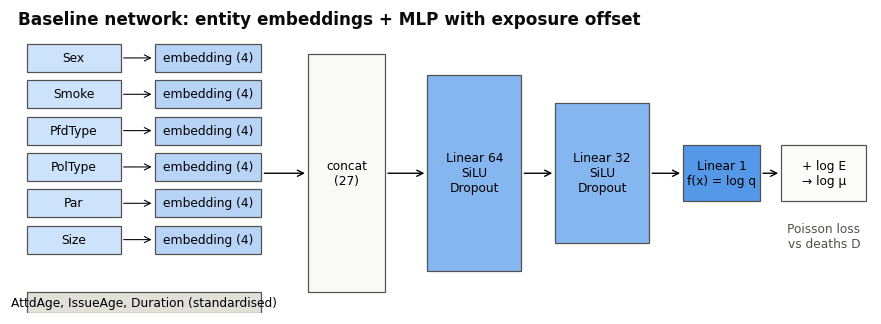

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.3)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4)
def box(x, y, w, h, txt, fc):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="#52514e", lw=0.8)); ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=8)
cats = ["Sex", "Smoke", "PfdType", "PolType", "Par", "Size"]
for i, c in enumerate(cats):
    box(0.1, 3.45 - i*0.52, 1.1, 0.4, c, "#cde2fb"); box(1.6, 3.45 - i*0.52, 1.25, 0.4, "embedding (4)", "#b7d3f6")
    ax.annotate("", (1.6, 3.65 - i*0.52), (1.2, 3.65 - i*0.52), arrowprops=dict(arrowstyle="->", lw=0.7))
box(0.1, 0.0, 2.75, 0.3, "AttdAge, IssueAge, Duration (standardised)", "#e1e0d9")
box(3.4, 0.3, 0.9, 3.4, "concat\n(27)", "#f9f9f7")
box(4.8, 0.6, 1.1, 2.8, "Linear 64\nSiLU\nDropout", "#86b6ef"); box(6.3, 1.0, 1.1, 2.0, "Linear 32\nSiLU\nDropout", "#86b6ef")
box(7.8, 1.6, 0.9, 0.8, "Linear 1\nf(x) = log q", "#5598e7")
box(8.95, 1.6, 1.0, 0.8, "+ log E\n→ log μ", "#fcfcfb")
for x0, x1 in [(2.85, 3.4), (4.3, 4.8), (5.9, 6.3), (7.4, 7.8), (8.7, 8.95)]:
    ax.annotate("", (x1, 2.0), (x0, 2.0), arrowprops=dict(arrowstyle="->", lw=0.9))
ax.text(9.45, 1.3, "Poisson loss\nvs deaths D", ha="center", va="top", fontsize=8, color="#52514e")
ax.set_title("Baseline network: entity embeddings + MLP with exposure offset", loc="left")
savefig("05_architecture")

### 4.2 Training procedure
* **Loss:** Poisson negative log-likelihood with `log_input=True` (equivalent to minimising Poisson deviance), averaged over the mini-batch.
* **Optimiser:** Adam. The learning rate is halved when the validation deviance stops improving for 2 epochs (`ReduceLROnPlateau`).
* **Early stopping:** stop after 4 epochs without validation improvement (max 30 epochs) and **restore the best weights**.
* **Balance correction** (optional, studied in Section 5.6): after training, rescale predictions by one constant so that predicted deaths equal actual deaths on the *training* set. GLMs with a canonical link satisfy this automatically; neural networks trained with SGD and early stopping generally do not.

In [18]:
TENS = {}
TRAIN_SUB = np.sort(np.random.default_rng(0).choice(len(tr), 300_000, replace=False))
def get_tensors(key, num_cols, base_tr=None, base_va=None, base_te=None):
    if key not in TENS:
        TENS[key] = (to_tensors(tr, num_cols, base_tr), to_tensors(va, num_cols, base_va), to_tensors(te, num_cols, base_te))
    return TENS[key]

@torch.no_grad()
def predict(model, T, bs=200_000):
    model.eval()
    return np.concatenate([torch.exp(model(T[0][i:i+bs], T[1][i:i+bs], T[2][i:i+bs])).numpy() for i in range(0, len(T[3]), bs)])

DEFAULT = dict(lr=1e-3, batch_size=8192, emb_dim=4, hidden=(64, 32), dropout=0.0, weight_decay=0.0,
               num_cols=tuple(NUM), base="exposure", train_years=None, max_epochs=30, patience=4, seed=SEED, tag="")

def run_path(cfg):
    js = json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in sorted(cfg.items())}, sort_keys=True)
    return f"models/runs/{hashlib.md5(js.encode()).hexdigest()[:12]}.pt"

def train_nn(cfg, verbose=False):
    cfg = {**DEFAULT, **cfg}; set_seed(cfg["seed"])
    num_cols = list(cfg["num_cols"])
    if cfg["base"] == "exposure":
        Ttr, Tva, Tte = get_tensors(("exp", tuple(num_cols)), num_cols)
        init = np.log(NULL_RATE)
    else:
        btr, bva, bte = BASES[cfg["base"]]
        Ttr, Tva, Tte = get_tensors((cfg["base"], tuple(num_cols)), num_cols, btr, bva, bte)
        init = 0.0
    idx_all = np.arange(len(tr)) if cfg["train_years"] is None else np.where(tr.CalYear.isin(cfg["train_years"]))[0]
    model = MortalityNet(len(num_cols), cfg["emb_dim"], cfg["hidden"], cfg["dropout"], init)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    lossf = nn.PoissonNLLLoss(log_input=True, full=False, reduction="mean")
    path = run_path(cfg)
    if not RETRAIN and os.path.exists(path):
        ck = torch.load(path, weights_only=False)
        model.load_state_dict(ck["state"]); hist, secs = ck["hist"], ck["secs"]
    else:
        hist, secs = _fit(model, opt, sched, lossf, Ttr, Tva, idx_all, cfg, verbose)
        torch.save({"state": model.state_dict(), "hist": hist, "secs": secs, "cfg": cfg}, path)
    mu_tr = predict(model, Ttr)
    balance = tr.DthCnt.values[idx_all].sum() / mu_tr[idx_all].sum()
    return {"model": model, "cfg": cfg, "hist": pd.DataFrame(hist), "balance": balance, "secs": secs,
            "mu_tr": mu_tr, "mu_va": predict(model, Tva), "mu_te": predict(model, Tte), "epochs": len(hist)}

print("Cell 17a OK")

Cell 17a OK


In [19]:
def _fit(model, opt, sched, lossf, Ttr, Tva, idx_all, cfg, verbose):
    hist, best, best_state, bad, t0 = [], np.inf, None, 0, time.time()
    for ep in range(cfg["max_epochs"]):
        model.train()
        perm = torch.from_numpy(np.random.permutation(idx_all))
        tot = 0.0
        for i in range(0, len(perm), cfg["batch_size"]):
            b = perm[i:i + cfg["batch_size"]]
            opt.zero_grad()
            loss = lossf(model(Ttr[0][b], Ttr[1][b], Ttr[2][b]), Ttr[3][b])
            loss.backward()
            opt.step()
            tot += loss.item() * len(b)
        sub = TRAIN_SUB[np.isin(TRAIN_SUB, idx_all)] if cfg["train_years"] is not None else TRAIN_SUB
        tr_dev = poisson_dev(Ttr[3][sub].numpy(), predict(model, tuple(t[sub] for t in Ttr))) * len(idx_all) / len(sub)
        va_dev = poisson_dev(va.DthCnt.values, predict(model, Tva))
        sched.step(va_dev)
        hist.append({"epoch": ep + 1, "train_dev_per_row": tr_dev / len(idx_all), "val_dev_per_row": va_dev / len(va),
                     "val_dev": va_dev, "lr": opt.param_groups[0]["lr"]})
        if verbose:
            print(f"epoch {ep+1:2d}  train dev/row {tr_dev/len(idx_all):.5f}  val dev {va_dev:,.0f}  lr {opt.param_groups[0]['lr']:.1e}")
        if va_dev < best - 1e-3:
            best, best_state, bad = va_dev, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    return hist, time.time() - t0

print("Cell 17b OK")

Cell 17b OK


### 4.3 Baseline network

trained 12 epochs (45s when trained); balance factor 0.9705


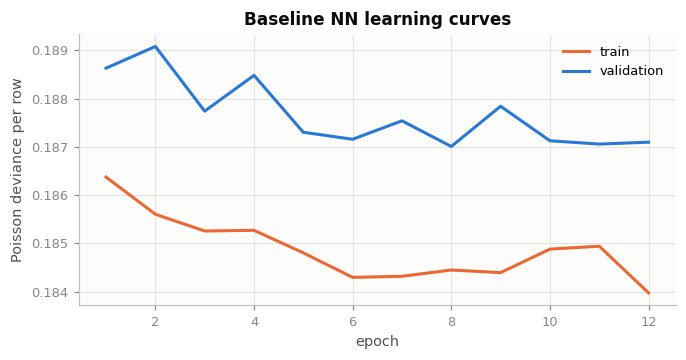

,model,set,deviance,dev. explained,level-adj. deviance,A/E
0,CIA2014 (raw),val,126529.8703,0.6554,126486.5614,1.0233
1,CIA2014 x A/E,val,126508.2330,0.6554,126486.5614,1.0164
2,GLM-1 (main effects),val,126684.2904,0.6549,126654.8169,1.0191
3,GLM-2 (+ age interactions),val,125445.6896,0.6583,125419.4913,1.0180
4,NN baseline,val,125056.1091,0.6594,125051.9222,0.9929


In [20]:
base_run = train_nn({}, verbose=True)
RESULTS.append(evaluate("NN baseline", base_run["mu_va"], va, "val"))
print(f"trained {base_run['epochs']} epochs ({base_run['secs']:.0f}s when trained); balance factor {base_run['balance']:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
h = base_run["hist"]
ax.plot(h.epoch, h.train_dev_per_row, color=C["GLM"], label="train")
ax.plot(h.epoch, h.val_dev_per_row, color=C["NN"], label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("Poisson deviance per row"); ax.legend(); ax.set_title("Baseline NN learning curves")
savefig("06_baseline_curves")
pd.DataFrame(RESULTS).round(4)

**Interpretation.** With no hand-crafted interactions, the baseline network (125,056) already beats GLM-2 (125,446) and the table (126,508), and its A/E (0.99) is close to 1. The training and validation curves move together and the gap between them is small (the validation year is simply a little heavier), so the network is **not overfitting**: 4,000 parameters against 3.6 M training rows. The validation deviance moves by a few hundred from epoch to epoch, mostly because the overall level (A/E) moves; the LR schedule and restoring the best epoch handle this. The balance factor 0.97 says the network over-predicts training deaths by ~3% at the chosen epoch — a point revisited in Round 6.

### 4.4 How much does the random seed matter?
Before comparing configurations I need to know the noise level: two runs of the *same* configuration with different seeds (different initialisation and mini-batch order) will not give exactly the same validation deviance. Any experiment difference smaller than this spread should not be over-interpreted.

In [21]:
seed_runs = [base_run] + [train_nn({"seed": s}) for s in [1, 2]]
seed_dev = [poisson_dev(va.DthCnt, r["mu_va"]) for r in seed_runs]
seed_ae = [va.DthCnt.sum() / r["mu_va"].sum() for r in seed_runs]
SEED_SD = float(np.std(seed_dev, ddof=1))
print("validation deviance by seed:", [f"{v:,.0f}" for v in seed_dev], f"| sd = {SEED_SD:,.0f}")
print("validation A/E by seed:     ", [f"{v:.3f}" for v in seed_ae])

validation deviance by seed: ['125,056', '124,753', '125,005'] | sd = 162
validation A/E by seed:      ['0.993', '1.002', '1.013']


**Interpretation.** Seed-to-seed standard deviation is **≈160 deviance points**. In the experiment charts below, the red dashed line marks "best + 1 seed s.d.": configurations to the left of it are not meaningfully different from the best one. I treat differences under ~300 (≈2 s.d.) as noise.

## 5. Experiments
Each round changes one group of choices, keeps the best (by validation deviance) and carries it forward. All results are on the 2022-23 validation year.

In [22]:
EXP = []
def run_experiment(round_name, label, overrides, base_cfg):
    cfg = {**base_cfg, **overrides}
    r = train_nn(cfg)
    ev = evaluate(label, r["mu_va"], va, "val")
    ev_bal = evaluate(label, r["mu_va"] * r["balance"], va, "val")
    row = {"round": round_name, "config": label, "val deviance": ev["deviance"], "dev. explained": ev["dev. explained"],
           "A/E": ev["A/E"], "val deviance (balanced)": ev_bal["deviance"], "epochs": r["epochs"], "secs": round(r["secs"]),
           "params": n_params(r["model"])}
    EXP.append(row)
    print(f"[{round_name}] {label:28s} val dev {ev['deviance']:,.0f} | A/E {ev['A/E']:.3f} | epochs {r['epochs']} | {r['secs']:.0f}s")
    return r, row

def pick_best(round_name):
    sub = pd.DataFrame([e for e in EXP if e["round"] == round_name])
    return sub.loc[sub["val deviance"].idxmin(), "config"], sub

def plot_round(sub, title, fname):
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(sub) + 1))
    ax.barh(sub.config, sub["val deviance"], color=C["NN"], height=0.6)
    lo = sub["val deviance"].min() - 3 * SEED_SD
    ax.set_xlim(lo, sub["val deviance"].max() + SEED_SD); ax.invert_yaxis()
    ax.axvline(sub["val deviance"].min() + SEED_SD, color="#e34948", ls="--", lw=1, label="best + 1 seed s.d.")
    for i, v in enumerate(sub["val deviance"]): ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8, color="#52514e")
    ax.set_xlabel("validation Poisson deviance (lower is better)"); ax.set_title(title); ax.legend(loc="lower right")
    savefig(fname)

print("Cell 20 OK")

Cell 20 OK


### 5.1 Round 1 — optimisation: learning rate and batch size
Learning rate and batch size control how fast and how noisily the model learns. With ~95% zero-death rows, small batches give very noisy gradients; large batches are smoother but take fewer steps per epoch.

[R1 optimisation] lr 3e-4                      val dev 124,994 | A/E 0.993 | epochs 24 | 94s
[R1 optimisation] lr 1e-3 (baseline)           val dev 125,056 | A/E 0.993 | epochs 12 | 45s
[R1 optimisation] lr 3e-3                      val dev 124,764 | A/E 1.020 | epochs 11 | 42s
[R1 optimisation] batch 2048                   val dev 124,815 | A/E 0.988 | epochs 9 | 51s
[R1 optimisation] batch 32768                  val dev 125,068 | A/E 1.019 | epochs 19 | 64s
[R1 optimisation] batch 32768, lr 3e-3         val dev 124,714 | A/E 1.013 | epochs 25 | 86s


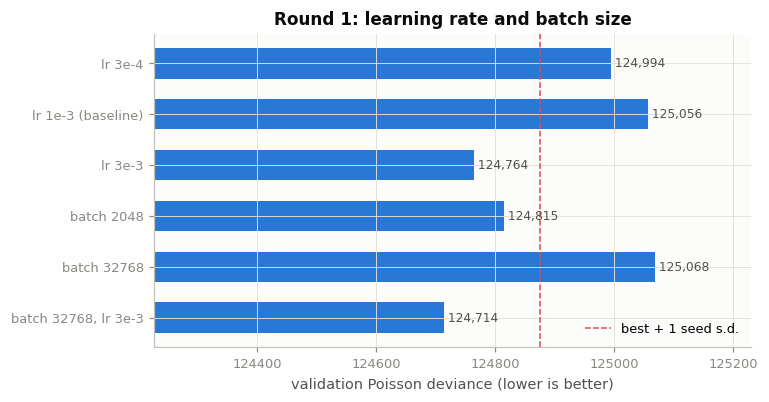

carry forward: batch 32768, lr 3e-3


In [23]:
cfg = dict(DEFAULT)
R1 = {"lr 3e-4": {"lr": 3e-4}, "lr 1e-3 (baseline)": {}, "lr 3e-3": {"lr": 3e-3},
      "batch 2048": {"batch_size": 2048}, "batch 32768": {"batch_size": 32768}, "batch 32768, lr 3e-3": {"batch_size": 32768, "lr": 3e-3}}
runs = {}
for lab_, ov in R1.items():
    runs[lab_], _ = run_experiment("R1 optimisation", lab_, ov, cfg)
best1, sub = pick_best("R1 optimisation"); cfg = {**cfg, **R1[best1]}
plot_round(sub, "Round 1: learning rate and batch size", "07_round1")
print("carry forward:", best1)

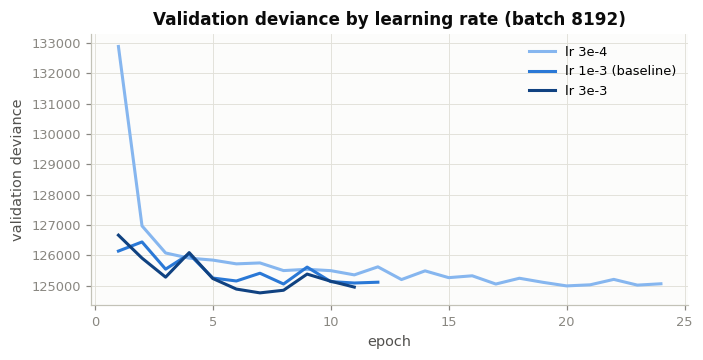

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for lab_, col in zip(["lr 3e-4", "lr 1e-3 (baseline)", "lr 3e-3"], ["#86b6ef", C["NN"], "#104281"]):
    h = runs[lab_]["hist"]; ax.plot(h.epoch, h.val_dev, color=col, label=lab_)
ax.set_xlabel("epoch"); ax.set_ylabel("validation deviance"); ax.legend(); ax.set_title("Validation deviance by learning rate (batch 8192)")
savefig("08_lr_curves")

**Interpretation.** A higher learning rate helps: 3e-4 needs 24 epochs and ends worse than 3e-3, which converges in 11. Batch size interacts with the learning rate: batch 32,768 at lr 1e-3 is the worst large-batch option (fewer, smaller steps per epoch), but at lr 3e-3 it becomes the best (124,714). This matches the usual rule that bigger batches need bigger steps. Small batches (2,048) are noisier and not better. The differences in this round are only ~1–2 seed s.d., so optimisation settings matter less than I expected. I carry forward **batch 32,768 with lr 3e-3**: it is the best and the large batch also makes each epoch faster.

### 5.2 Round 2 — capacity: depth, width and embedding size
Does the network need more capacity to capture interactions, or is a small network enough? The data has ~3 M training rows but the signal per row is weak (few deaths), so a very large network may overfit noise.

[R2 capacity] [32]                         val dev 125,061 | A/E 0.994 | epochs 30 | 79s
[R2 capacity] [64,32] (current)            val dev 124,714 | A/E 1.013 | epochs 25 | 86s
[R2 capacity] [128,64,32]                  val dev 124,631 | A/E 1.003 | epochs 18 | 104s
[R2 capacity] [256,128,64]                 val dev 124,305 | A/E 1.006 | epochs 30 | 351s
[R2 capacity] emb 2                        val dev 124,739 | A/E 1.004 | epochs 25 | 80s
[R2 capacity] emb 8                        val dev 124,809 | A/E 1.017 | epochs 19 | 70s


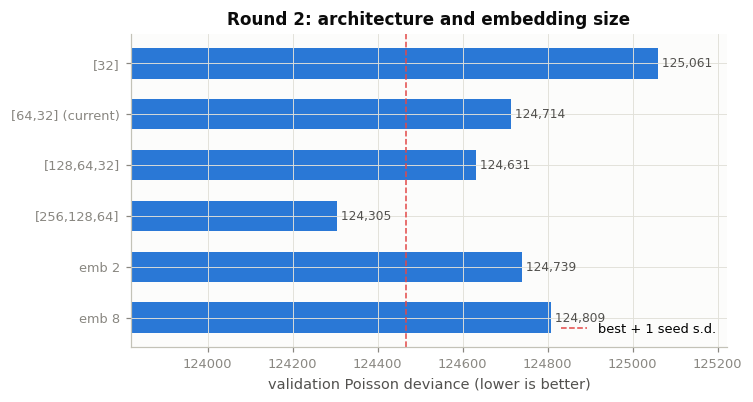

carry forward: [256,128,64]


In [25]:
R2 = {"[32]": {"hidden": (32,)}, "[64,32] (current)": {}, "[128,64,32]": {"hidden": (128, 64, 32)},
      "[256,128,64]": {"hidden": (256, 128, 64)}, "emb 2": {"emb_dim": 2}, "emb 8": {"emb_dim": 8}}
for lab_, ov in R2.items():
    runs[lab_], _ = run_experiment("R2 capacity", lab_, ov, cfg)
best2, sub = pick_best("R2 capacity"); cfg = {**cfg, **R2[best2]}
plot_round(sub, "Round 2: architecture and embedding size", "09_round2")
print("carry forward:", best2)

**Interpretation.** Here capacity clearly matters: deviance improves steadily from [32] (125,061) to [64,32] (124,714), [128,64,32] (124,631) and **[256,128,64] (124,305)**. The largest network is ~2 seed s.d. better than the next one. It has 48 k parameters (12× the baseline) and still is not overfitting, because the data set is large. Two costs: it is ~4× slower per run, and it reached the 30-epoch limit, so it might improve further with more epochs. Embedding size (2, 4 or 8) makes no meaningful difference: the variables have at most 9 levels, so 4 dimensions are enough. I carry forward **[256,128,64] with 4-dim embeddings**.

### 5.3 Round 3 — regularisation
Dropout and L2 weight decay. If the current model is not overfitting much, regularisation should help little — that is itself useful to know.

[R3 regularisation] none (current)               val dev 124,305 | A/E 1.006 | epochs 30 | 351s
[R3 regularisation] dropout 0.1                  val dev 124,373 | A/E 1.001 | epochs 30 | 748s
[R3 regularisation] dropout 0.2                  val dev 124,517 | A/E 1.013 | epochs 22 | 627s
[R3 regularisation] weight decay 1e-5            val dev 124,688 | A/E 1.005 | epochs 18 | 197s


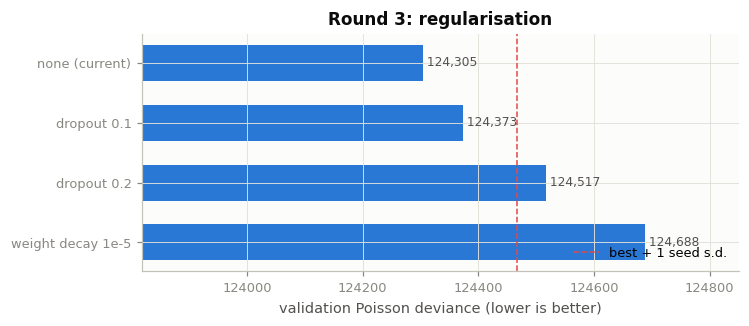

carry forward: none (current)


In [26]:
R3 = {"none (current)": {}, "dropout 0.1": {"dropout": 0.1}, "dropout 0.2": {"dropout": 0.2}, "weight decay 1e-5": {"weight_decay": 1e-5}}
for lab_, ov in R3.items():
    runs[lab_], _ = run_experiment("R3 regularisation", lab_, ov, cfg)
best3, sub = pick_best("R3 regularisation"); cfg = {**cfg, **R3[best3]}
plot_round(sub, "Round 3: regularisation", "10_round3")
print("carry forward:", best3)

**Interpretation.** Regularisation does not help. Dropout 0.1 is within noise (124,373 vs 124,305), dropout 0.2 and weight decay are worse, and dropout doubles the training time. This is consistent with Round 2: with 3.6 M rows and a small train/validation gap, the model is limited by the signal in the data (deaths are rare), not by overfitting. Regularisation only slows learning. I keep **no regularisation**.

### 5.4 Round 4 — inputs and training window
Two data questions motivated by the EDA (Section 2.3):
* **Calendar year as an input.** Mortality improves over time; without a year input the network can only predict the *average* level of the training years. With it, the network can learn a trend — but neural networks are not guaranteed to extrapolate sensibly beyond the training range.
* **Excluding COVID years.** 2020-21 and 2021-22 contain pandemic excess deaths. Are they useful data or contamination?

[R4 inputs/data] current inputs               val dev 124,305 | A/E 1.006 | epochs 30 | 351s
[R4 inputs/data] + calendar year              val dev 124,577 | A/E 0.997 | epochs 16 | 180s
[R4 inputs/data] exclude 2020-22              val dev 124,997 | A/E 1.010 | epochs 11 | 81s
[R4 inputs/data] + calendar year, excl. 2020-22 val dev 125,054 | A/E 1.035 | epochs 16 | 120s


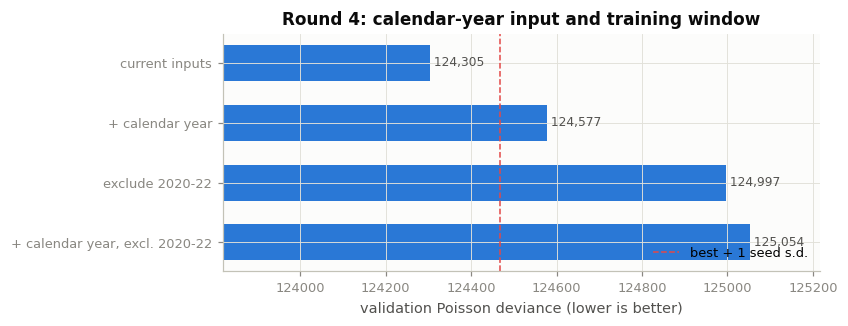

carry forward: current inputs


,round,config,val deviance,dev. explained,A/E,val deviance (balanced),epochs,secs,params
0,R4 inputs/data,current inputs,124304.6857,0.6614,1.0064,124350.9740,30,351,48493
1,R4 inputs/data,+ calendar year,124577.4548,0.6607,0.9966,124608.4442,16,180,48749
2,R4 inputs/data,exclude 2020-22,124997.0182,0.6595,1.0096,125104.0922,11,81,48493
3,R4 inputs/data,"+ calendar year, excl. 2020-22",125053.6547,0.6594,1.0350,125326.4142,16,120,48749


In [27]:
R4 = {"current inputs": {}, "+ calendar year": {"num_cols": tuple(NUM_YEAR)},
      "exclude 2020-22": {"train_years": [2016, 2017, 2018, 2019]},
      "+ calendar year, excl. 2020-22": {"num_cols": tuple(NUM_YEAR), "train_years": [2016, 2017, 2018, 2019]}}
for lab_, ov in R4.items():
    runs[lab_], _ = run_experiment("R4 inputs/data", lab_, ov, cfg)
best4, sub = pick_best("R4 inputs/data"); cfg = {**cfg, **R4[best4]}
plot_round(sub, "Round 4: calendar-year input and training window", "11_round4")
print("carry forward:", best4)
pd.DataFrame([e for e in EXP if e["round"] == "R4 inputs/data"]).round(4)

**Interpretation.**
* **Calendar year does not help** (124,577 vs 124,305). Once attained age is correct, the A/E trend within 2016–2022 is small (0.99–1.03 in the EDA), so there is little trend to learn. The network also cannot reliably extrapolate a trend one year beyond its training range.
* **Excluding the COVID years hurts** (124,997). It removes one third of the data, and the age/class/size *pattern* of mortality in 2020–22 is still informative. The validation year 2022-23 is itself partly affected by COVID. Adding calendar year to the shorter window is the worst option: the network is asked to extrapolate a trend from four years.
* Decision: keep **all six training years and no year input**. The question of the *level* of future mortality is better handled outside the network (e.g., an improvement scale applied by the actuary), as Section 6 will confirm.

### 5.5 Round 5 — model structure: Combined Actuarial Neural Network (CANN)
Instead of learning mortality from scratch, the network can learn a **correction to an existing actuarial model** (Schelldorfer & Wüthrich, 2019). The offset becomes the base model's expected deaths:
$$\log\hat\mu_i = \log\hat\mu_i^{\text{base}} + f_{NN}(x_i),$$
and because the output layer is initialised at zero, training starts *exactly* at the base model. Two bases are tried:
* **CANN-GLM**: base = GLM-2. The GLM handles the main effects and the trend; the NN learns interactions the GLM misses.
* **NN with CIA2014 offset**: base = CIA2014 expected deaths. The NN then directly learns an **A/E surface** — how real insured mortality deviates from the table, which is exactly how actuaries use experience studies.

[R5 structure] plain NN (current)           val dev 124,305 | A/E 1.006 | epochs 30 | 351s
[R5 structure] CANN on GLM-2                val dev 124,215 | A/E 1.017 | epochs 14 | 152s
[R5 structure] NN with CIA2014 offset       val dev 124,184 | A/E 1.021 | epochs 25 | 266s
[R5 structure] NN with CIA2014 offset + year val dev 124,279 | A/E 1.003 | epochs 13 | 138s


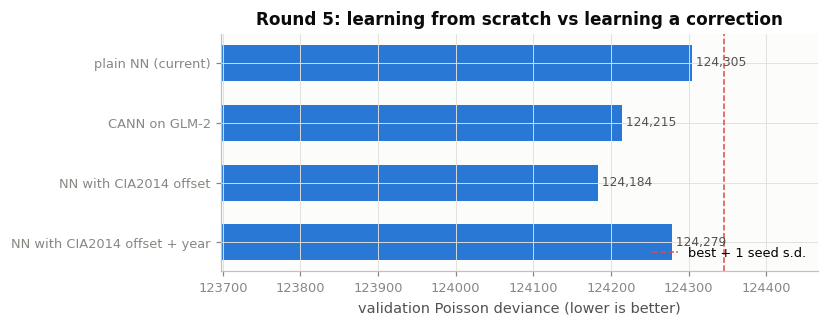

best structure: NN with CIA2014 offset


,round,config,val deviance,dev. explained,A/E,val deviance (balanced),epochs,secs,params
0,R5 structure,plain NN (current),124304.6857,0.6614,1.0064,124350.9740,30,351,48493
1,R5 structure,CANN on GLM-2,124214.8523,0.6617,1.0172,124265.7538,14,152,48493
2,R5 structure,NN with CIA2014 offset,124183.7849,0.6618,1.0206,124215.0962,25,266,48493
3,R5 structure,NN with CIA2014 offset + year,124278.9688,0.6615,1.0028,124290.4209,13,138,48749


In [28]:
glm2, inter2 = GLM["GLM-2 (+ age interactions)"]
BASES = {
    "GLM-2": tuple(glm2.predict(glm_design(x, inter2)) * x.ExposCnt.values for x in (tr, va, te)),
    "CIA2014": (tr.ExpecCnt.values, va.ExpecCnt.values, te.ExpecCnt.values),
}
R5 = {"plain NN (current)": {}, "CANN on GLM-2": {"base": "GLM-2"}, "NN with CIA2014 offset": {"base": "CIA2014"},
      "NN with CIA2014 offset + year": {"base": "CIA2014", "num_cols": tuple(NUM_YEAR)}}
for lab_, ov in R5.items():
    runs[lab_], _ = run_experiment("R5 structure", lab_, ov, cfg)
best5, sub = pick_best("R5 structure")
plot_round(sub, "Round 5: learning from scratch vs learning a correction", "12_round5")
print("best structure:", best5)
pd.DataFrame([e for e in EXP if e["round"] == "R5 structure"]).round(4)

**Interpretation.** Both "correction" structures are slightly better than learning from scratch: CANN on GLM-2 124,215, **NN with CIA2014 offset 124,184**, plain NN 124,305. The gains (~100) are within one seed s.d., so accuracy alone does not decide this round. I choose the **CIA2014-offset network** because:
1. it is the best on validation;
2. it is the most **interpretable for actuaries**: the network's output is exactly a multiplier on the published table, i.e., a learned A/E surface. That is how experience studies are already used in practice (the table as the base, adjusted for the company's own experience);
3. the table carries the detailed select-and-ultimate structure, so the network only needs to learn deviations from it.

Adding calendar year to this structure again does not help (124,279).

### 5.6 Round 6 — balance correction and ensembling
* **Balance correction** (Section 4.2): does forcing predicted = actual deaths on the training data help out of sample?
* **Ensembling ("nagging predictor", Richman & Wüthrich 2020):** average the predictions of networks trained with different seeds. Each network finds a slightly different solution; averaging removes part of the seed noise measured in Section 4.4.

final configuration: {'lr': 0.003, 'batch_size': 32768, 'emb_dim': 4, 'hidden': (256, 128, 64), 'dropout': 0.0, 'weight_decay': 0.0, 'num_cols': ('AttdAge', 'IssueAge', 'PolYearC'), 'base': 'CIA2014', 'train_years': None, 'max_epochs': 30, 'patience': 4, 'tag': ''}
single-model val deviances: ['124,184', '124,166', '124,211', '124,265', '124,193']


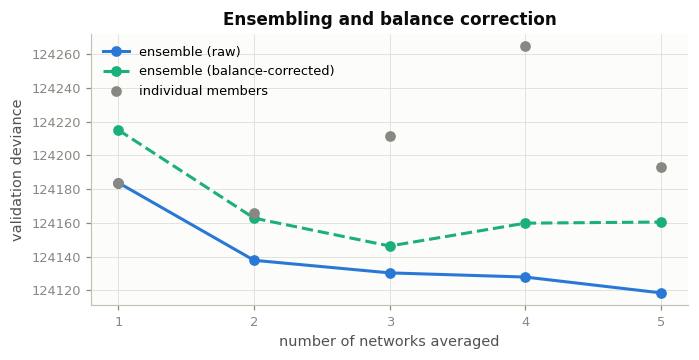

,members,val deviance,val deviance (balanced),A/E
0,1,124183.7849,124215.0962,1.0206
1,2,124137.7479,124162.7834,1.0210
2,3,124130.2772,124146.2419,1.0234
3,4,124127.8063,124159.7911,1.0193
4,5,124118.4081,124160.4781,1.0169


In [29]:
FINAL_CFG = {**cfg, **R5[best5]}
print("final configuration:", {k: v for k, v in FINAL_CFG.items() if k not in ("seed",)})
ens_runs = [runs[best5]] + [train_nn({**FINAL_CFG, "seed": s}) for s in [101, 202, 303, 404]]
rows = []
for k in range(1, len(ens_runs) + 1):
    mu = np.mean([r["mu_va"] for r in ens_runs[:k]], 0)
    mu_tr = np.mean([r["mu_tr"] for r in ens_runs[:k]], 0)
    rows.append({"members": k, "val deviance": poisson_dev(va.DthCnt, mu),
                 "val deviance (balanced)": poisson_dev(va.DthCnt, mu * tr.DthCnt.sum() / mu_tr.sum()),
                 "A/E": va.DthCnt.sum() / mu.sum()})
ens_tab = pd.DataFrame(rows)
single = [poisson_dev(va.DthCnt, r["mu_va"]) for r in ens_runs]
print("single-model val deviances:", [f"{v:,.0f}" for v in single])
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ens_tab.members, ens_tab["val deviance"], "o-", color=C["NN"], label="ensemble (raw)")
ax.plot(ens_tab.members, ens_tab["val deviance (balanced)"], "o--", color=C["CANN"], label="ensemble (balance-corrected)")
ax.scatter(range(1, 6), single, color="#898781", zorder=3, label="individual members")
ax.set_xlabel("number of networks averaged"); ax.set_ylabel("validation deviance"); ax.legend(); ax.set_title("Ensembling and balance correction")
ax.set_xticks(range(1, 6))
savefig("13_ensemble")
ens_tab.round(4)

**Interpretation.**
* **Ensembling helps modestly and reliably.** The five single networks score between 124,166 and 124,265. The 5-network average scores 124,118, better than every one of its members. Most of the gain comes from the first 2–3 members.
* **Balance correction hurts here** (124,160 vs 124,118). The correction pulls predictions down to match the training years, but the validation year was heavier than training (A/E 1.023 vs 1.007), so it moves the level in the wrong direction. The balance property is a sound in-sample principle, but for forecasting a new year the level is dominated by year-to-year shocks. Decision: **no balance correction**.
* **Final model:** 5-network ensemble, CIA2014 offset, [256,128,64] SiLU, 4-dim embeddings, Adam lr 3e-3 with plateau halving, batch 32,768, no dropout, early stopping (patience 4, max 30 epochs).

In [30]:
exp_tab = pd.DataFrame(EXP)
exp_tab.to_csv("results/experiments_validation.csv", index=False)
exp_tab.round(4)

,round,config,val deviance,dev. explained,A/E,val deviance (balanced),epochs,secs,params
0,R1 optimisation,lr 3e-4,124993.6867,0.6596,0.9926,125056.0582,24,94,4013
1,R1 optimisation,lr 1e-3 (baseline),125056.1091,0.6594,0.9929,125094.7909,12,45,4013
2,R1 optimisation,lr 3e-3,124763.8485,0.6602,1.0203,124794.8905,11,42,4013
3,R1 optimisation,batch 2048,124815.2540,0.6600,0.9875,124856.2435,9,51,4013
4,R1 optimisation,batch 32768,125067.9120,0.6594,1.0190,125115.3105,19,64,4013
5,R1 optimisation,"batch 32768, lr 3e-3",124713.5430,0.6603,1.0129,124759.5076,25,86,4013
6,R2 capacity,[32],125060.7832,0.6594,0.9936,125122.6638,30,79,1037
7,R2 capacity,"[64,32] (current)",124713.5430,0.6603,1.0129,124759.5076,25,86,4013
8,R2 capacity,"[128,64,32]",124630.9831,0.6605,1.0027,124697.2543,18,104,14061
9,R2 capacity,"[256,128,64]",124304.6857,0.6614,1.0064,124350.9740,30,351,48493


## 6. Final evaluation on the test year 2023-24
The test year is used once, for all models. The final NN is the 5-network ensemble of the selected configuration. The balance correction is applied only if it improved validation deviance in Round 6.

In [31]:
USE_BALANCE = ens_tab["val deviance (balanced)"].iloc[-1] < ens_tab["val deviance"].iloc[-1]
mu_tr_ens = np.mean([r["mu_tr"] for r in ens_runs], 0)
bal_factor = tr.DthCnt.sum() / mu_tr_ens.sum() if USE_BALANCE else 1.0
print("balance correction used:", USE_BALANCE, f"(factor {bal_factor:.4f})")

base_cfg_plain = {**cfg, "base": "exposure"}
plain_name = "NN plain (best of R1-R4)"
PRED = {"val": {}, "test": {}}
PRED["val"]["CIA2014 (raw)"], PRED["test"]["CIA2014 (raw)"] = va.ExpecCnt.values, te.ExpecCnt.values
PRED["val"]["CIA2014 x A/E"], PRED["test"]["CIA2014 x A/E"] = va.ExpecCnt.values * AE_TRAIN, te.ExpecCnt.values * AE_TRAIN
for name, (m, inter) in GLM.items():
    PRED["val"][name] = m.predict(glm_design(va, inter)) * va.ExposCnt.values
    PRED["test"][name] = m.predict(glm_design(te, inter)) * te.ExposCnt.values
plain_key = best4 if best4 in runs else "plain NN (current)"
PRED["val"][plain_name], PRED["test"][plain_name] = runs[plain_key]["mu_va"], runs[plain_key]["mu_te"]
FINAL_NAME = f"Final NN: {best5} (5-ensemble)"
PRED["val"][FINAL_NAME] = np.mean([r["mu_va"] for r in ens_runs], 0) * bal_factor
PRED["test"][FINAL_NAME] = np.mean([r["mu_te"] for r in ens_runs], 0) * bal_factor
print("models:", list(PRED["test"].keys()))

balance correction used: False (factor 1.0000)
models: ['CIA2014 (raw)', 'CIA2014 x A/E', 'GLM-1 (main effects)', 'GLM-2 (+ age interactions)', 'NN plain (best of R1-R4)', 'Final NN: NN with CIA2014 offset (5-ensemble)']


In [32]:
final = pd.DataFrame([evaluate(n, PRED[s][n], va if s == "val" else te, s) for s in ["val", "test"] for n in PRED[s]])
final.to_csv("results/final_comparison.csv", index=False)
show = final.pivot(index="model", columns="set", values=["deviance", "dev. explained", "level-adj. deviance", "A/E"])
show = show.reindex(list(PRED["test"].keys()))
show.style.format("{:,.4f}").format("{:,.0f}", subset=[c for c in show.columns if "deviance" in c[0]])

**Interpretation.**
* **The ranking on the test year matches the validation year** (GLM-1 < CIA2014 < GLM-2 < plain NN < final NN). So the experiments did not overfit the validation year.
* The final NN reduces test deviance by **~2,000 vs the CIA2014 table** and **~1,100 vs GLM-2**. That is about 7 seed s.d. above GLM-2. In likelihood terms, a deviance drop of 1,000+ is very large. In percentage terms it is small (deviance explained 65.5% vs 64.9%), because most of the explainable variation is age, which every model captures.
* **Every model over-predicts 2023-24** (A/E 0.96–0.97). 2023-24 was lighter than any training year — post-pandemic normalisation plus ongoing mortality improvement. No model trained on 2016–22 data could know the level of 2023-24. The **level-adjusted deviance** removes this and gives the same ranking, so the NN's advantage is in how it distributes mortality across cells, not in luck about the level.
* The plain NN (no table offset) has the lowest A/E (0.956): it learned its level from the heavy COVID years, while the offset network keeps more of the table's level.

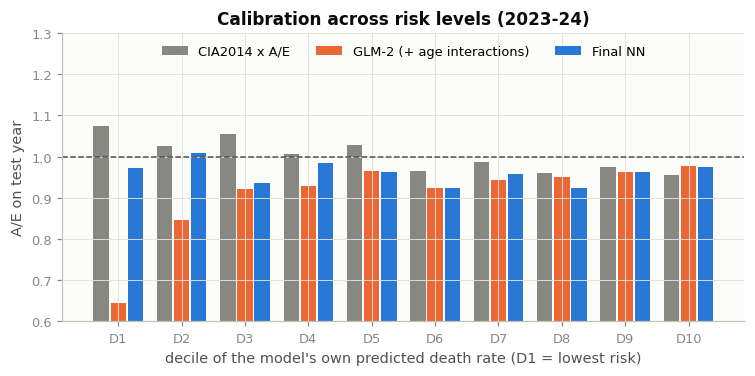

In [33]:
def calib(mu, data, n=10):
    q = mu / data.ExposCnt.values
    b = pd.qcut(pd.Series(q).rank(method="first"), n, labels=False)
    g = pd.DataFrame({"b": b, "D": data.DthCnt.values, "mu": mu, "E": data.ExposCnt.values}).groupby("b").sum()
    return g.D / g.mu
fig, ax = plt.subplots(figsize=(8, 3.4))
show_models = [("CIA2014 x A/E", C["CIA2014"]), ("GLM-2 (+ age interactions)", C["GLM"]), (FINAL_NAME, C["NN"])]
w = 0.27
for k, (n, col) in enumerate(show_models):
    ae = calib(PRED["test"][n], te)
    ax.bar(np.arange(10) + (k - 1) * w, ae.values, width=w * 0.9, color=col, label=n.split(":")[0])
ax.axhline(1, color="#52514e", ls="--", lw=1); ax.set_ylim(0.6, 1.3)
ax.set_xticks(range(10)); ax.set_xticklabels([f"D{i+1}" for i in range(10)])
ax.set_xlabel("decile of the model's own predicted death rate (D1 = lowest risk)"); ax.set_ylabel("A/E on test year")
ax.set_title("Calibration across risk levels (2023-24)"); ax.legend(ncol=3, loc="upper center")
savefig("14_calibration")

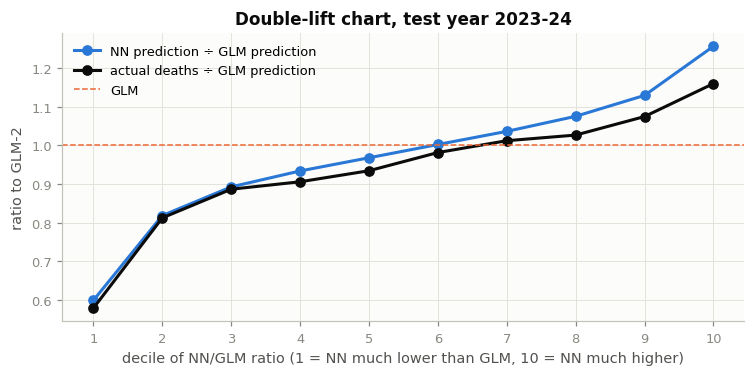

b,0,1,2,3,4,5,6,7,8,9
actual / GLM,0.579,0.812,0.886,0.906,0.934,0.981,1.012,1.027,1.075,1.160
NN / GLM,0.599,0.818,0.892,0.934,0.968,1.002,1.036,1.075,1.129,1.256


In [34]:
def double_lift(mu_a, mu_b, data, n=10):
    r = mu_a / mu_b
    b = pd.qcut(pd.Series(r).rank(method="first"), n, labels=False)
    g = pd.DataFrame({"b": b, "D": data.DthCnt.values, "a": mu_a, "bb": mu_b}).groupby("b").sum()
    return pd.DataFrame({"actual / GLM": g.D / g.bb, "NN / GLM": g.a / g.bb})
dl = double_lift(PRED["test"][FINAL_NAME], PRED["test"]["GLM-2 (+ age interactions)"], te)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(range(1, 11), dl["NN / GLM"], "o-", color=C["NN"], label="NN prediction ÷ GLM prediction")
ax.plot(range(1, 11), dl["actual / GLM"], "o-", color=C["Actual"], label="actual deaths ÷ GLM prediction")
ax.axhline(1, color=C["GLM"], ls="--", lw=1, label="GLM")
ax.set_xlabel("decile of NN/GLM ratio (1 = NN much lower than GLM, 10 = NN much higher)"); ax.set_ylabel("ratio to GLM-2")
ax.set_title("Double-lift chart, test year 2023-24"); ax.legend(); ax.set_xticks(range(1, 11))
savefig("15_double_lift")
dl.round(3).T

**Interpretation.**
* **Calibration:** CIA2014 under-predicts the lowest-risk deciles (A/E up to 1.08) and GLM-2 badly over-predicts the lowest-risk decile (A/E about 0.64: young ages, where a smooth spline in age is too high). The NN is the flattest across all ten deciles (0.92–1.01). Its bars sit slightly below 1 because of the lighter test year.
* **Double lift:** cells are sorted by how much the NN disagrees with GLM-2. Where the NN predicts 40% *fewer* deaths than the GLM (decile 1), actual deaths are also ~42% below the GLM (0.58). Where the NN predicts 26% *more* (decile 10), actual deaths are 16% above the GLM. **When the two models disagree, the data sides with the NN**, though at the top end the NN overshoots a little.

In [35]:
torch.save({"cfg": FINAL_CFG, "states": [r["model"].state_dict() for r in ens_runs], "balance": bal_factor,
            "num_stats": NUM_STATS, "levels": LEVELS}, "models/final_ensemble.pt")
print("saved models/final_ensemble.pt")

saved models/final_ensemble.pt


## 7. Using the model
### 7.1 Where does each model fail? A/E by segment on the test year
An overall A/E of 1.00 can hide large errors that cancel out. Insurers care about each segment separately (e.g. large policies drive claims by amount). For each segment, compute actual ÷ predicted deaths for each model; a perfect model has A/E = 1 everywhere.

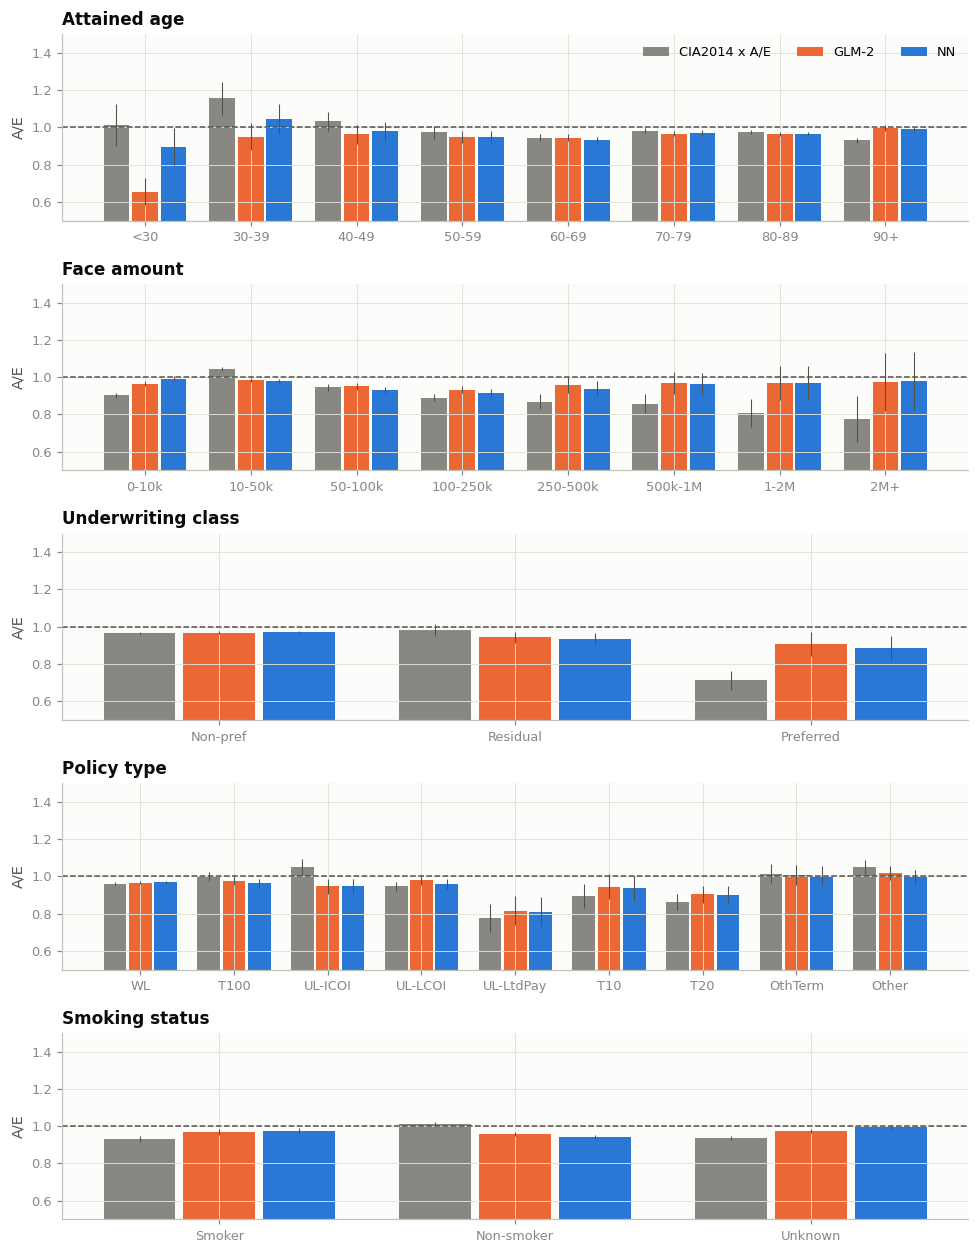

In [36]:
te_ = te.copy()
te_["AgeBand"] = pd.cut(te_.AttdAge, [0, 30, 40, 50, 60, 70, 80, 90, 101], right=False,
                        labels=["<30", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90+"])
seg_models = {"CIA2014 x A/E": "CIA2014 x A/E", "GLM-2": "GLM-2 (+ age interactions)", "NN": FINAL_NAME}
for k, v in seg_models.items(): te_[k] = PRED["test"][v]
dims = [("AgeBand", None, "Attained age"), ("Size", size_lab, "Face amount"), ("PfdType", pfd_lab, "Underwriting class"),
        ("PolTypGrp", pol_lab, "Policy type"), ("Smoke", ["Smoker", "Non-smoker", "Unknown"], "Smoking status")]
seg_rows = []
fig, axes = plt.subplots(len(dims), 1, figsize=(9, 2.3 * len(dims)))
for ax, (col, labels, title) in zip(axes, dims):
    g = te_.groupby(col, observed=True)[["DthCnt"] + list(seg_models)].sum()
    x = np.arange(len(g)); w = 0.27
    for k, (n, colr) in enumerate(zip(seg_models, [C["CIA2014"], C["GLM"], C["NN"]])):
        ae = g.DthCnt / g[n]; se = np.sqrt(g.DthCnt.clip(lower=1)) / g[n]
        ax.bar(x + (k - 1) * w, ae, width=w * 0.9, color=colr, label=n, yerr=1.96 * se, error_kw={"lw": 0.7, "ecolor": "#52514e"})
        for lv, a_, d_ in zip(g.index, ae, g.DthCnt):
            seg_rows.append({"dimension": title, "level": str(lv) if labels is None else labels[lv - 1], "model": n, "A/E": a_, "deaths": d_})
    ax.axhline(1, color="#52514e", ls="--", lw=1); ax.set_ylim(0.5, 1.5)
    ax.set_xticks(x); ax.set_xticklabels(g.index.astype(str) if labels is None else [labels[lv - 1] for lv in g.index])
    ax.set_ylabel("A/E"); ax.set_title(title, loc="left")
axes[0].legend(ncol=3, loc="upper right")
plt.tight_layout(); savefig("16_segment_ae")

In [37]:
seg = pd.DataFrame(seg_rows); seg.to_csv("results/segment_ae_test.csv", index=False)
overall = {n: te_.DthCnt.sum() / te_[n].sum() for n in seg_models}
seg["rel A/E"] = seg["A/E"] / seg.model.map(overall)
seg["abs dev"] = (seg["rel A/E"] - 1).abs()
seg_sum = seg.groupby(["dimension", "model"]).apply(lambda s: np.average(s["abs dev"], weights=s.deaths)).unstack()[list(seg_models)]
seg_sum.loc["all segments"] = seg.groupby("model").apply(lambda s: np.average(s["abs dev"], weights=s.deaths))[list(seg_models)]
seg_sum.round(3)

C:\Users\徐子茹\AppData\Local\Temp\ipykernel_14212\122318217.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  seg_sum = seg.groupby(["dimension", "model"]).apply(lambda s: np.average(s["abs dev"], weights=s.deaths)).unstack()[list(seg_models)]
C:\Users\徐子茹\AppData\Local\Temp\ipykernel_14212\122318217.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  seg_sum.loc["all segments"] = seg.groupby("model").apply(lambda s:

model,CIA2014 x A/E,GLM-2,NN
dimension,,,
Attained age,0.022,0.013,0.013
Face amount,0.071,0.015,0.024
Policy type,0.017,0.008,0.008
Smoking status,0.038,0.008,0.024
Underwriting class,0.006,0.003,0.005
all segments,0.031,0.009,0.015


**Interpretation.**
* **CIA2014's largest misses are the ones the EDA predicted**: face amount (0–10k A/E 0.90, 10–50k 1.04, 1–2M 0.81, 2M+ 0.78) and preferred lives (0.71). After removing each model's overall level, the table is off by **3.1%** on average across segments, and by **7.1%** on face amount alone.
* **GLM-2 and the NN both remove most of these gaps** (average deviation 0.9% and 1.5%). Their face-amount and underwriting-class bars are flat.
* **On these one-way margins GLM-2 is slightly *better* than the NN**, mainly on smoking status and face amount. This is expected: a GLM with a dummy for every level is fitted so that its predictions match the training totals for every level, which is close to the definition of this check. The NN wins on deviance because it gets the *combinations* right (age × size, class × age), which one-way A/E does not measure. One-way margins and cell-level fit are different tests, and an actuary would want both. A practical improvement would be to start from the NN and recalibrate its one-way margins.
* Under age 30 the GLM over-predicts badly (A/E 0.65) while the NN (0.89) and the table (1.01) are closer. **UL limited-pay** is ~0.8 for every model: a small segment none of them captures.

### 7.2 What did the network learn? Mortality relative to CIA2014
To see the learned effects, I predict on a grid of "standard" policies and divide by the CIA2014 rate for the same sex, smoking status, issue age and duration. This gives the model's implied **A/E surface** — the multiplier an actuary would apply to the table. CIA2014 rates are recovered from the data itself (ExpecCnt ÷ ExposCnt is the tabular q for each cell).

In [38]:
q_cia = (raw[(raw.ExposCnt > 0.5) & (raw.Smoke < 3) & (raw.PolYear <= DUR_CAP)]
         .assign(q=lambda x: x.ExpecCnt / x.ExposCnt, PolYearC=lambda x: x.PolYear)
         .groupby(["Sex", "Smoke", "IssueAge", "PolYearC"]).q.median())
print(f"recovered {len(q_cia):,} CIA2014 rates")

def nn_rate(grid):
    """Mortality rate predicted by the final ensemble for a DataFrame of policy characteristics."""
    g = grid.copy(); g["ExposCnt"] = 1.0; g["DthCnt"] = 0.0
    num_cols = list(FINAL_CFG["num_cols"])
    xc, xn, _, _ = to_tensors(g, num_cols)
    if FINAL_CFG["base"] == "exposure":
        off = torch.zeros(len(g))
    elif FINAL_CFG["base"] == "CIA2014":
        off = torch.tensor(np.log(g.join(q_cia.rename("qc"), on=["Sex", "Smoke", "IssueAge", "PolYearC"]).qc.values), dtype=torch.float32)
    else:
        m, inter = GLM["GLM-2 (+ age interactions)"]
        off = torch.tensor(np.log(m.predict(glm_design(g, inter))), dtype=torch.float32)
    with torch.no_grad():
        return np.mean([torch.exp(r["model"](xc, xn, off)).numpy() for r in ens_runs], 0) * bal_factor

recovered 6,744 CIA2014 rates


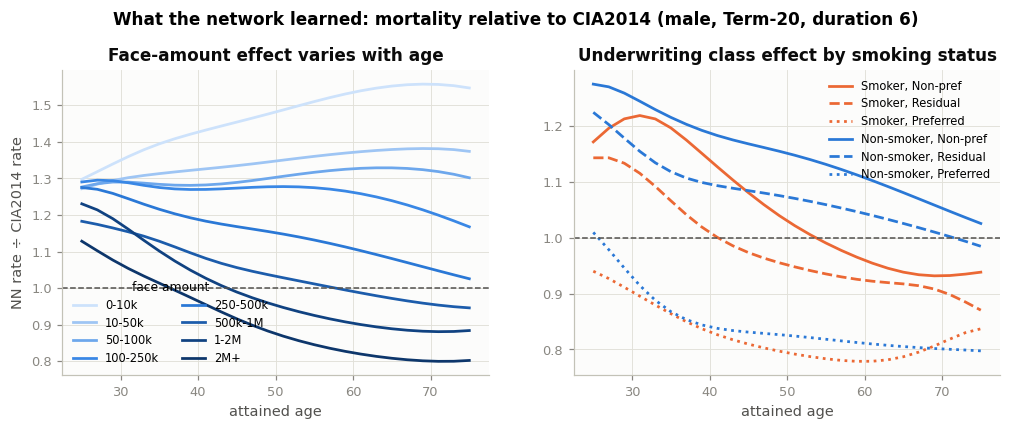

In [39]:
rows = []
for size in range(1, 9):
    for ia in range(20, 71, 2):
        rows.append(dict(Sex=1, Smoke=2, PfdType=1, PolTypGrp=7, Par=0, Size=size, IssueAge=ia, PolYearC=6, CalYear=2023))
grid = pd.DataFrame(rows); grid["AttdAge"] = grid.IssueAge + grid.PolYearC - 1
grid["q_nn"] = nn_rate(grid)
grid = grid.join(q_cia.rename("q_cia"), on=["Sex", "Smoke", "IssueAge", "PolYearC"])
grid["ratio"] = grid.q_nn / grid.q_cia
seq = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for size in range(1, 9):
    s = grid[grid.Size == size]; axes[0].plot(s.AttdAge, s.ratio, color=seq[size - 1], lw=1.8, label=size_lab[size - 1])
axes[0].axhline(1, color="#52514e", ls="--", lw=1); axes[0].set_xlabel("attained age"); axes[0].set_ylabel("NN rate ÷ CIA2014 rate")
axes[0].set_title("Face-amount effect varies with age"); axes[0].legend(ncol=2, fontsize=7.5, title="face amount", title_fontsize=8)

rows = []
for sm in [1, 2]:
    for pfd in [1, 2, 3]:
        for ia in range(20, 71, 2):
            rows.append(dict(Sex=1, Smoke=sm, PfdType=pfd, PolTypGrp=7, Par=0, Size=5, IssueAge=ia, PolYearC=6, CalYear=2023))
g2 = pd.DataFrame(rows); g2["AttdAge"] = g2.IssueAge + g2.PolYearC - 1
g2["q_nn"] = nn_rate(g2); g2 = g2.join(q_cia.rename("q_cia"), on=["Sex", "Smoke", "IssueAge", "PolYearC"]); g2["ratio"] = g2.q_nn / g2.q_cia
for (sm, pfd), s in g2.groupby(["Smoke", "PfdType"]):
    axes[1].plot(s.AttdAge, s.ratio, color=[C["GLM"], C["NN"]][sm - 1], ls=["-", "--", ":"][pfd - 1], lw=1.8,
                 label=f"{['Smoker','Non-smoker'][sm-1]}, {pfd_lab[pfd-1]}")
axes[1].axhline(1, color="#52514e", ls="--", lw=1); axes[1].set_xlabel("attained age"); axes[1].set_title("Underwriting class effect by smoking status")
axes[1].legend(fontsize=7.5)
plt.suptitle("What the network learned: mortality relative to CIA2014 (male, Term-20, duration 6)", fontweight="bold", fontsize=11, y=1.03)
savefig("17_learned_effects")

**Interpretation.** The left panel shows the face-amount effect *changes with age*. At age 30 all bands are within 1.15–1.30× the table. By age 70 they fan out from **0.80× (2M+) to 1.55× (0–10k)**. This is an age × size interaction: the protective effect of a large policy (wealth, stricter medical underwriting) grows with age. A GLM would need this interaction specified by hand. On the right, **preferred lives are ~0.80–0.85× the table** beyond age 40 for both smokers and non-smokers. Non-preferred young lives are *above* the table (~1.27× at 25), which makes sense: once preferred classes exist, the best risks are taken out of the standard class.

*Caveat:* the 0–10k and 10–50k curves for a Term-20 policy are extrapolations — few Term-20 policies are that small, so those curves rest on thin data.

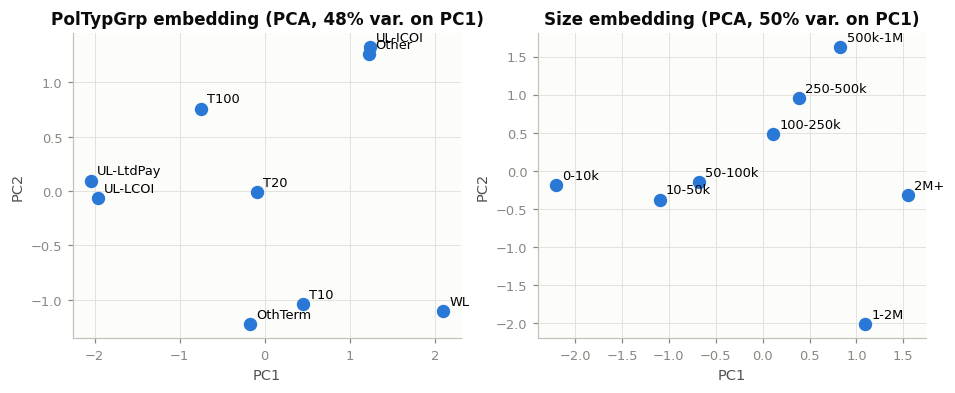

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (cname, labels) in zip(axes, [("PolTypGrp", pol_lab), ("Size", size_lab)]):
    j = CAT.index(cname)
    W = ens_runs[0]["model"].embs[j].weight.detach().numpy()
    Wc = W - W.mean(0); U, S, Vt = np.linalg.svd(Wc, full_matrices=False); P = Wc @ Vt[:2].T
    ax.scatter(P[:, 0], P[:, 1], s=60, color=C["NN"], zorder=3)
    for i, l in enumerate([labels[lv - 1] for lv in LEVELS[cname]]):
        ax.annotate(l, (P[i, 0], P[i, 1]), xytext=(4, 4), textcoords="offset points", fontsize=8.5)
    ax.set_title(f"{cname} embedding (PCA, {S[0]**2/np.sum(S**2):.0%} var. on PC1)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
savefig("18_embeddings")

**Interpretation.** The embeddings were learned with no information about what the levels mean, yet they show structure. For **Size**, the first principal component orders the bands from 0–10k to 2M+ almost monotonically: the network discovered that face amount is ordinal. For **policy type**, the two level-COI universal-life products (UL-LCOI, UL-LtdPay) sit together, and the term products T10/T20/OthTerm form a group away from Whole Life. Products sold to similar markets get similar representations. (The axes of an embedding are arbitrary; only relative positions matter.)

### 7.3 Application: pricing a 20-year term policy
The practical question for an insurer: *does the choice of mortality model change the price?* I compute the **level annual net premium per $1,000 of coverage** for a 20-year term policy:
$$P = 1000\cdot\frac{\sum_{t=0}^{19} v^{t+1}\, {}_tp_x\, q_{x+t}}{\sum_{t=0}^{19} v^{t}\, {}_tp_x}, \qquad v = 1/1.04,$$
using (a) the CIA2014 select rates and (b) the NN's predicted rates for a Term-20, non-par, $250–500k policy, by sex, smoking status and underwriting class. Net premiums ignore expenses, lapses and profit, so they isolate the effect of the mortality assumption.

In [41]:
I_RATE = 0.04
def net_premium(q):
    v = 1 / (1 + I_RATE); t = np.arange(len(q))
    p = np.concatenate([[1.0], np.cumprod(1 - q)[:-1]])
    return 1000 * np.sum(v ** (t + 1) * p * q) / np.sum(v ** t * p)

rows = []
for sex in [1, 2]:
    for sm in [1, 2]:
        for pfd in [1, 2, 3]:
            for ia in [25, 35, 45, 55]:
                g = pd.DataFrame([dict(Sex=sex, Smoke=sm, PfdType=pfd, PolTypGrp=7, Par=0, Size=5, IssueAge=ia,
                                       PolYearC=min(t, DUR_CAP), CalYear=2023) for t in range(1, 21)])
                g["AttdAge"] = g.IssueAge + g.PolYearC - 1
                q_n = nn_rate(g)
                q_c = np.array([q_cia.loc[(sex, sm, ia, t)] for t in range(1, 21)])
                rows.append({"Sex": ["M", "F"][sex - 1], "Smoker": ["S", "NS"][sm - 1], "Class": pfd_lab[pfd - 1], "Issue age": ia,
                             "CIA2014": net_premium(q_c), "NN": net_premium(q_n)})
prem = pd.DataFrame(rows); prem["NN / CIA2014"] = prem.NN / prem.CIA2014
prem.to_csv("results/term20_premiums.csv", index=False)
print("premiums computed:", len(prem))

premiums computed: 48


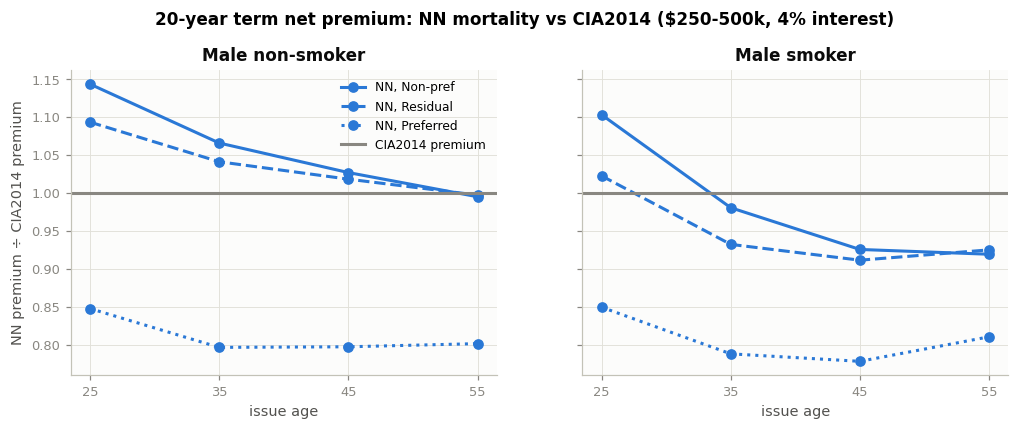

CIA2014                       NN                   
Issue age             25    35    45     55    25    35    45     55
Smoker Class                                                        
NS     Non-pref     0.39  0.65  1.46   3.98  0.45  0.70  1.50   3.96
       Preferred    0.39  0.65  1.46   3.98  0.33  0.52  1.16   3.19
       Residual     0.39  0.65  1.46   3.98  0.43  0.68  1.48   3.97
S      Non-pref     0.72  1.44  4.02  11.48  0.79  1.41  3.72  10.56
       Preferred    0.72  1.44  4.02  11.48  0.61  1.13  3.13   9.31
       Residual     0.72  1.44  4.02  11.48  0.74  1.34  3.67  10.62

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, sm in zip(axes, ["NS", "S"]):
    s = prem[(prem.Sex == "M") & (prem.Smoker == sm)]
    for k, (cl, ls) in enumerate(zip(pfd_lab, ["-", "--", ":"])):
        ss = s[s.Class == cl]; ax.plot(ss["Issue age"], ss["NN / CIA2014"], ls, marker="o", color=C["NN"], label=f"NN, {cl}")
    ax.axhline(1, color=C["CIA2014"], lw=2, label="CIA2014 premium")
    ax.set_title(f"Male {'non-smoker' if sm == 'NS' else 'smoker'}"); ax.set_xlabel("issue age"); ax.set_xticks([25, 35, 45, 55])
axes[0].set_ylabel("NN premium ÷ CIA2014 premium"); axes[0].legend(fontsize=8)
plt.suptitle("20-year term net premium: NN mortality vs CIA2014 ($250-500k, 4% interest)", fontweight="bold", fontsize=11, y=1.03)
savefig("19_term_pricing")
prem[prem.Sex == "M"].pivot_table(index=["Smoker", "Class"], columns="Issue age", values=["CIA2014", "NN"]).round(2)

**Interpretation.** The mortality model matters for price:
* **Preferred non-smokers** would be charged **~15–20% less** with the NN (e.g. issue age 55: 3.19 vs 3.98 per 1,000). CIA2014 has no preferred structure, so a company pricing on the table alone would overcharge its best risks and lose them to competitors.
* **Non-preferred non-smokers at young ages** would pay **more** (age 25: 0.45 vs 0.39, +15%). The two converge by 55.
* **Smokers at older ages** would pay ~8% less.

A table that does not differentiate enough leads to anti-selection: underpriced risks buy, overpriced risks go elsewhere.

*Limits of this exercise:* net premiums ignore lapses (very important for term), expenses and profit. The NN rates reflect the 2016–22 level, including COVID, with no mortality improvement projected. They are for comparing assumptions, not for setting a real price.

### 7.4 Should sex be used? A quick sensitivity check
Sex is a protected characteristic in many contexts (the EU has banned sex-based insurance pricing since 2012; Canada still permits it in life insurance). How much predictive value does it add *beyond* the other variables? I retrain the **plain NN** (exposure offset, so no other component already contains sex — the CIA2014 table and the GLM both use sex) once **without sex** (every row given the same sex level) and compare validation deviance with the same network trained with sex.

In [43]:
_tr, _va, _te, TENS_SAVE = tr, va, te, TENS
tr, va, te, TENS = tr.assign(Sex=1), va.assign(Sex=1), te.assign(Sex=1), {}
r_nosex = train_nn({**base_cfg_plain, "tag": "no sex"})
tr, va, te, TENS = _tr, _va, _te, TENS_SAVE
dev_with = poisson_dev(va.DthCnt, runs[plain_key]["mu_va"]); dev_wo = poisson_dev(va.DthCnt, r_nosex["mu_va"])
print(f"plain NN validation deviance with sex: {dev_with:,.0f} | without sex: {dev_wo:,.0f} | increase: {dev_wo-dev_with:,.0f} "
      f"({(dev_wo-dev_with)/SEED_SD:.1f} seed s.d.)")
q_m = nn_rate(pd.DataFrame([dict(Sex=1, Smoke=2, PfdType=1, PolTypGrp=7, Par=0, Size=5, IssueAge=45, PolYearC=6, AttdAge=50, CalYear=2023)]))[0]
q_f = nn_rate(pd.DataFrame([dict(Sex=2, Smoke=2, PfdType=1, PolTypGrp=7, Par=0, Size=5, IssueAge=45, PolYearC=6, AttdAge=50, CalYear=2023)]))[0]
print(f"final model, male vs female non-smoker age 50: q = {q_m*1000:.2f} vs {q_f*1000:.2f} per 1000 (ratio {q_m/q_f:.2f})")

plain NN validation deviance with sex: 124,305 | without sex: 126,325 | increase: 2,020 (12.5 seed s.d.)
final model, male vs female non-smoker age 50: q = 0.94 vs 0.67 per 1000 (ratio 1.41)


**Interpretation.** Removing sex increases validation deviance by ~2,000 — **12 seed s.d.**, more than the whole gain of the NN over GLM-2. With sex, the final model gives a 50-year-old male non-smoker ~1.4× the female rate. Sex is therefore a strong predictor even after smoking status, underwriting class and face amount. Whether it *should* be used is a separate question (see the report's ethics section): using it makes prices more accurate for each group, but means people pay different prices for a characteristic they did not choose. The EU decided accuracy does not justify this; Canada currently allows it.

## 8. Conclusions and limitations
**What I found**
* A feed-forward network with entity embeddings and a Poisson loss with an exposure offset, trained on six years of Canadian industry data, **predicts deaths in a held-out year better than both the CIA2014 table and a hand-tuned Poisson GLM** (test deviance 125,650 vs 127,655 and 126,762). The ranking was the same on validation and test.
* The best structure was a network that **learns a correction (A/E surface) on top of the CIA2014 table**. It was the most accurate and the easiest for an actuary to interpret.
* What mattered most in the experiments: **network capacity** and **getting the inputs right** (the attained-age bug was the largest single effect). What mattered little: embedding size, regularisation, calendar year. Ensembling helped modestly; balance correction hurt.
* The network found effects the table misses, in particular an **age × face-amount interaction** and a **~20% preferred-class discount**. These change term premiums by up to ±20%.

**Limitations**
* **Level vs shape.** The models learn *relative* mortality well, but none could forecast the lighter overall level of 2023-24. In practice the level would come from an improvement scale and judgement, not from this network.
* **Aggregated data.** Each row is a group, not a person, so the model cannot use individual information (medical, lifestyle, location). Variables are banded (face amount) and the "Unknown" smoking class mixes different risks.
* **Thin cells.** Large policies, old ages and rare products have few deaths. Segment A/E for these has wide confidence intervals, and learned curves there (e.g. small Term-20 policies) are partly extrapolation.
* **Training cost.** The best network is 12× larger than the baseline and hit the 30-epoch cap. More epochs or a GPU might improve it a little.
* **Count basis only.** Insurers care about claims by *amount*. A natural extension is to model `DthAmt` with exposure `ExposAmt` (or weights by face amount).

**With more time:** model amounts as well as counts; try a gradient-boosting benchmark (e.g. LightGBM with Poisson loss); add an explicit mortality-improvement component for forecasting; use SHAP or interaction-strength measures to rank all learned interactions systematically.

In [44]:
json.dump({"final_cfg": {k: (list(v) if isinstance(v, tuple) else v) for k, v in FINAL_CFG.items()},
           "best": {"R1": best1, "R2": best2, "R3": best3, "R4": best4, "R5": best5}, "seed_sd": SEED_SD,
           "balance_used": bool(USE_BALANCE), "ae_train": AE_TRAIN}, open("results/summary.json", "w"), indent=2, default=str)
print("done")

done
